# load libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import scipy.stats as st
from statsmodels.stats.multitest import multipletests
import pickle
import os
import datetime
from sklearn.preprocessing import MinMaxScaler
sns.set_context('paper')
import gseapy
# gseapy.get_library_name()
import warnings
warnings.filterwarnings("ignore")
import sys
sys.path.append('/lustre1/home/martinmikl/sshanas/bin')
from div import *

sns.set_context('paper')
plt.rcParams.update({
    'font.size': 10 * 0.6,
    'axes.titlesize': 10 * 0.6,
    'axes.labelsize': 10 * 0.6,
    'xtick.labelsize': 10 * 0.6,
    'ytick.labelsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'figure.titlesize': 12 * 0.6,
    'legend.title_fontsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans']
})

def nnow():
    print(datetime.datetime.now().strftime('%Y-%m-%d  %H:%M:%S'))
nnow()

s_colors =  ["#ff6f61", "#1f77b4", "#2ca02c"] 
smts_palette = pickle.load(open('smts_palette.pkl', 'rb'))
smtsd_palette = pickle.load(open('smtsd_palette.pkl', 'rb'))

X = 'div' ; Y = 'meanisofdiv'

pth = os.getcwd() + '/'

source_data_path = pth + 'source_data/'
supplementary_data_path = pth + 'supplementary_data/'

if not os.path.isdir(pth + 'figs_tdiv/'):
    os.mkdir(pth + 'figs_tdiv/')
if not os.path.isdir(pth + 'tables_tdiv/'):
    os.mkdir(pth + 'tables_tdiv/')
if not os.path.isdir(pth + 'tables_main/'):
    os.mkdir(pth + 'tables_main/')

2026-10-13  15:23:50


# load data

In [ ]:
input_path = '/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_upstream_git/'
tpm = pd.read_csv(input_path  + 'gene_tpm.csv.gz', index_col=0)
tpm = np.log2(tpm + 1)
tpm_untn = pd.read_csv(input_path  + 'gene_tpm.csv.gz', index_col=0)
div = pd.read_csv(input_path  + 'div1.csv.gz', index_col=0)
nis = pd.read_csv(input_path  + 'nisoforms_expressed.csv.gz', index_col=0)
metadata = pd.read_csv(input_path  + 'metadata.csv.gz', index_col=0)
gene_info = pd.read_csv(input_path  + 'gene_annotation.csv.gz', index_col=0)
cellular_div_corr_transcriptome_div = pd.read_csv(input_path + 'CDIV_TDIV_pearosnr.csv.gz')
pth = os.getcwd() + '/'
source_data_path = pth + 'source_data/'
supplementary_data_path = pth + 'supplementary_data/'
    
abb_SMTS = {t: t.replace(' Tissue', '').replace('Gland', 'G.').replace('Vessel', 'V.') for t in metadata.SMTS.unique()}
metadata.to_csv(source_data_path + '3cdef4bc_metadata.csv.gz', compression='gzip', index=True)

nnow()

2026-10-07  19:51:20


# functions to make dataframes

In [21]:
def scale_with_MinMax(smpl):
    scaler = MinMaxScaler(feature_range=(10**-7, 1))
    plot_data = tpm_untn[[smpl]]
    plot_data = plot_data[plot_data > 0].dropna().sort_values(plot_data.columns[0], ascending=False)

    plot_data = plot_data.assign(minmax = scaler.fit_transform(plot_data[[smpl]]))
    plot_data = plot_data.assign(percentiles = plot_data['minmax'].rank(pct=True) * 100).sort_values('minmax', ascending=True)
    return plot_data

# functions to make plots

In [17]:
nnow()
def format_small_number(v):
    if 'e' in str(v):
        val, x, powerof = str(v).replace("e", " x 10^").split(' ')
        formatted = ''.join([f"{float(val):.2f}", x, powerof])
    else:
        formatted = f"{v:.2f}"
    return formatted


def annotpval(pv):
    if float(f'{pv:.2e}') == 0.00e+00:
        return 'p<10^-323'
    else:
        return f'p={pv:.2e}'

def style_axis(ax):
    ax.tick_params(length=2.5)
    ax.set_yticklabels(ax.get_yticklabels(), x=0)
    ax.set_xticklabels(ax.get_xticklabels(), ha='center', y=0)
    ax.set_xlabel(ax.get_xlabel(), labelpad=0)
    ax.set_ylabel(ax.get_ylabel(), labelpad=0)

2026-10-07  19:58:26


In [ ]:
pth = ''

2026-09-14  09:38:36
 
      
lineplots showing the maximum and minimum transcriptome diversity.
The lineplot shows scaled gene expression, in expressed genes (TPM>0) 
maximum diversity comes from SMTS: Testis, diversity index: 0.91, number of genes in plot: 15765
minimum diversity comes from SMTS: Blood, diversity index: 0.17, number of genes in plot: 13527
            
      


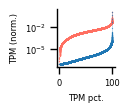

In [ ]:
maxdiv = metadata['div'].idxmax()
mindiv = metadata['div'].idxmin()

plot_data_max = scale_with_MinMax(smpl = maxdiv)
plot_data_min = scale_with_MinMax(smpl = mindiv)
nnow()
fig, ax = plt.subplots(1, 1, figsize=(0.75, 0.75))
sns.lineplot(data=plot_data_max, x='percentiles', y='minmax', color=s_colors[0], marker='h', markersize=1, linewidth = 0.25, alpha = 0.7, markeredgewidth=0,
             ax =ax)
sns.lineplot(data=plot_data_min, x='percentiles', y='minmax', color=s_colors[1], marker='h', markersize=1, linewidth = 0.25, alpha = 0.7, markeredgewidth=0,
             ax =ax)
ax.set_yscale('log')
ax.set(ylabel='TPM (norm.)', xlabel='TPM pct.')
style_axis(ax)
sns.despine()
# ax.text(s = f'{metadata.loc[metadata['div'].idxmax(), 'SMTS']}\n{metadata['div'].max():.2f}', x = 20, y = 14**-2, color = s_colors[0])
# ax.text(s = f'{metadata.loc[metadata['div'].idxmin(), 'SMTS']}\n{metadata['div'].min():.2f}', x = 20, y = 15**-5, color = s_colors[1])

fig.savefig(pth + 'figs_tdiv/' + 'min_max.T-DIV.lines.png', format='png', dpi=300, bbox_inches='tight')

print(f''' 
      
lineplots showing the maximum and minimum transcriptome diversity.
The lineplot shows scaled gene expression, in expressed genes (TPM>0) 
maximum diversity comes from SMTS: {metadata.loc[maxdiv, 'SMTS']}, diversity index: {metadata.loc[maxdiv, 'div']:.2f}, number of genes in plot: {len(plot_data_max)}
minimum diversity comes from SMTS: {metadata.loc[mindiv, 'SMTS']}, diversity index: {metadata.loc[mindiv, 'div']:.2f}, number of genes in plot: {len(plot_data_min)}
            
      ''')

plot_data_max.to_csv('tables_tdiv/max_TDIV.csv.gz', compression='gzip', index=True)
plot_data_min.to_csv('tables_tdiv/min_TDIV.csv.gz', compression='gzip', index=True)

In [ ]:
# nnow()
# maxdiv = metadata['div'].idxmax()
# mindiv = metadata['div'].idxmin()
# X = 'div' ; Y = 'meanisofdiv'
# def make_mean_err_per_SMTS(df):
#   mean_err_SMTS = metadata.groupby('SMTS')[['meanisofdiv',X]].mean().join(metadata.groupby('SMTS')[['meanisofdiv',X]].std().add_suffix('_err'))
#   mean_err_SMTS.reset_index(inplace=True)       
#   return mean_err_SMTS 
# # mean_err_SMTS = make_mean_err_per_SMTS(metadata[metadata.SMTS.isin(['Brain', 'Skin', 'Muscle', 'Testis'])])
# mean_err_SMTS = make_mean_err_per_SMTS(metadata)
# mean_err_SMTS['colors'] = mean_err_SMTS.SMTS.map(smts_palette)
# from matplotlib.collections import PatchCollection
# from matplotlib.patches import Rectangle, Patch
# fig, ax = plt.subplots(1, figsize=(2,2))
# sns.scatterplot(data=metadata, y = Y, x = X, edgecolor='none', c='silver', alpha = 0.3, s = 3)
# ax.set(ylabel='µ I-DIV', xlabel='T-DIV')
# sns.despine()
# fig.savefig(pth + 'figs_tdiv/' + 'idiv_tdiv.naked.scatter.png', format='png', dpi=300, bbox_inches='tight')
# sns.scatterplot(data=metadata.loc[[maxdiv]], y = Y, x = X, edgecolor='none', c=s_colors[0], alpha = 1, s = 3)
# sns.scatterplot(data=metadata.loc[[mindiv]], y = Y, x = X, edgecolor='none', c=s_colors[1], alpha = 1, s = 3)
# style_axis(ax)
# fig.savefig(pth + 'figs_tdiv/' + 'idiv_tdiv.min_max.scatter.png', format='png', dpi=300, bbox_inches='tight')

# for idx, subt in enumerate(mean_err_SMTS.SMTS.unique()):
#   artists = ax.errorbar(mean_err_SMTS.loc[idx, X], mean_err_SMTS.loc[idx, Y], 
#                         xerr=mean_err_SMTS.loc[idx, X + '_err'], yerr=mean_err_SMTS.loc[idx, Y + '_err'],
#                         ecolor=mean_err_SMTS.loc[idx, 'colors'], elinewidth=1, alpha=0.7, ms=3, mec='dimgrey', mew=0.5,
#                         markerfacecolor=mean_err_SMTS.loc[idx, 'colors'], fmt='h') # ecolor='C' + str(idx) fmt='none'

# xmin, xmax = ax.get_xlim()
# r, p = st.pearsonr(metadata[X], metadata[Y])
# ax.set_title(f'r={r:.2f}, p={format_small_number(p)}')


# legend_handles = [

#     Line2D([], [], marker='h', linestyle='None', markerfacecolor=smts_palette[t], markeredgecolor='none', markersize=5, label=t) for t in smts_palette.keys() if t in mean_err_SMTS.SMTS.unique()
    
#     ] + \
#       [Line2D([], [], marker='o', linestyle='None', markerfacecolor=s_colors[0], markeredgecolor='none', markersize=3, label='max T-DIV'),
#        Line2D([], [], marker='o', linestyle='None', markerfacecolor=s_colors[1], markeredgecolor='none', markersize=3, label='min T-DIV'),
#        Line2D([], [], marker='o', linestyle='None', markerfacecolor='silver', markeredgecolor='none', markersize=3, label='samples')]

# ax.legend(handles=legend_handles, bbox_to_anchor =(1.05, 1.1), loc='upper left', fontsize=6, ncols=2, frameon=False)

# fig.savefig(pth + 'figs_tdiv/' + 'idiv_tdiv.SMTS.scatter.png', format='png', dpi=300, bbox_inches='tight')

# print(f''' 
# scatterplot showing mean isoform diversity (y axis) VS transcriptome diversity (x axis). 
# every silver datapoint is a sample (n={len(metadata)}).
# hexagons are the mean isoform diversity and mean transcriptome diversty per SMTS tissue (n={metadata.SMTS.nunique()}). 
# error lines show the standard deviation per tissue for the mean isoform diversity or transcriptome diversity.
# minimum and maximum transcriptome diversity samples are highlighted in color, with their SMTS tissue name, transcriptome diversity and mean isoform diversity values.
# max T-DIV: {metadata.loc[maxdiv, "SMTS"]}, T-DIV={metadata.loc[maxdiv, "div"]:.2f}, µ I-DIV={metadata.loc[maxdiv, "meanisofdiv"]:.2f}
# min T-DIV: {metadata.loc[mindiv, "SMTS"]}, T-DIV={metadata.loc[mindiv, "div"]:.2f}, µ I-DIV={metadata.loc[mindiv, "meanisofdiv"]:.2f}
#       ''')

 
scatterplot showing mean isoform diversity (y axis) VS transcriptome diversity (x axis). 
every silver datapoint is a sample (n=4814).
hexagons are the mean isoform diversity and mean transcriptome diversty per SMTS tissue (n=25). 
error lines show the standard deviation per tissue for the mean isoform diversity or transcriptome diversity.
minimum and maximum transcriptome diversity samples are highlighted in color, with their SMTS tissue name, transcriptome diversity and mean isoform diversity values.
max T-DIV: Testis, T-DIV=0.91, µ I-DIV=0.54
min T-DIV: Blood, T-DIV=0.17, µ I-DIV=0.30
      


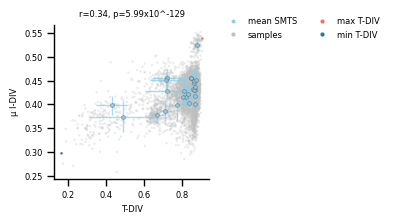

In [ ]:

fig, ax = plt.subplots(1, figsize=(2,2))
sns.scatterplot(data=metadata, y = Y, x = X, edgecolor='none', c='silver', alpha = 0.3, s = 3)
sns.scatterplot(data=metadata.loc[[maxdiv]], y = Y, x = X, edgecolor='none', c=s_colors[0], alpha = 1, s = 3)
sns.scatterplot(data=metadata.loc[[mindiv]], y = Y, x = X, edgecolor='none', c=s_colors[1], alpha = 1, s = 3)
for idx, subt in enumerate(mean_err_SMTS.SMTS.unique()):
  artists = ax.errorbar(mean_err_SMTS.loc[idx, X], mean_err_SMTS.loc[idx, Y], 
                        xerr=mean_err_SMTS.loc[idx, X + '_err'], yerr=mean_err_SMTS.loc[idx, Y + '_err'],
                        ecolor='skyblue', elinewidth=1, alpha=0.7, ms=3, mec='dimgrey', mew=0.5,
                        markerfacecolor='skyblue', fmt='h') # ecolor='C' + str(idx) fmt='none'

xmin, xmax = ax.get_xlim()
r, p = st.pearsonr(metadata[X], metadata[Y])
ax.set_title(f'r={r:.2f}, p={format_small_number(p)}')


legend_handles = [
      Line2D([], [], marker='h', linestyle='None', markerfacecolor='skyblue', markeredgecolor='none', markersize=3, label='mean SMTS'),
      Line2D([], [], marker='o', linestyle='None', markerfacecolor='silver', markeredgecolor='none', markersize=3, label='samples'),      
      Line2D([], [], marker='o', linestyle='None', markerfacecolor=s_colors[0], markeredgecolor='none', markersize=3, label='max T-DIV'),
      Line2D([], [], marker='o', linestyle='None', markerfacecolor=s_colors[1], markeredgecolor='none', markersize=3, label='min T-DIV')
]

ax.legend(handles=legend_handles, bbox_to_anchor =(1.05, 1.1), loc='upper left', fontsize=6, ncols=2, frameon=False)
ax.set(ylabel='µ I-DIV', xlabel='T-DIV')
style_axis(ax)
sns.despine()
fig.savefig(pth + 'figs_tdiv/' + 'idiv_tdiv.SMTS_nohue.scatter.png', format='png', dpi=300, bbox_inches='tight')
print(f''' 
scatterplot showing mean isoform diversity (y axis) VS transcriptome diversity (x axis). 
every silver datapoint is a sample (n={len(metadata)}).
hexagons are the mean isoform diversity and mean transcriptome diversty per SMTS tissue (n={metadata.SMTS.nunique()}). 
error lines show the standard deviation per tissue for the mean isoform diversity or transcriptome diversity.
minimum and maximum transcriptome diversity samples are highlighted in color, with their SMTS tissue name, transcriptome diversity and mean isoform diversity values.
max T-DIV: {metadata.loc[maxdiv, "SMTS"]}, T-DIV={metadata.loc[maxdiv, "div"]:.2f}, µ I-DIV={metadata.loc[maxdiv, "meanisofdiv"]:.2f}
min T-DIV: {metadata.loc[mindiv, "SMTS"]}, T-DIV={metadata.loc[mindiv, "div"]:.2f}, µ I-DIV={metadata.loc[mindiv, "meanisofdiv"]:.2f}
      ''')

mean_err_SMTS.to_csv('tables_tdiv/' + 'SMTS_mean.csv.gz', compression='gzip', index=True)
mean_err_SMTS.to_csv('tables_main/' + 'SMTS_mean.csv.gz', compression='gzip', index=True)

In [138]:
import plotly.express as px
import plotly.graph_objects as go
# fig, ax = plt.subplots(figsize=(2,2))
alpha = 0.5
px.scatter(mean_err_SMTS, x = 'div', y = 'meanisofdiv', 
                opacity = alpha,  hover_data=['SMTS'],
                width = 500 , height=500)

2026-09-14  09:40:27


 
dot plot which shows the pearson correlation of mean isoform diversity VS transcriptome diversity.
dot plot which shows the slope of mean isoform diversity VS transcriptome diversity.
      


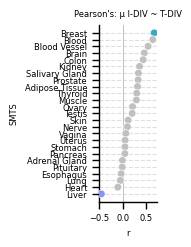

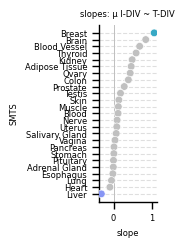

In [ ]:
nnow()
abb_SMTS = {t: t.replace(' Tissue', '').replace('Gland', 'G.').replace('Vessel', 'V.') for t in metadata.SMTS.unique()}
tissue_transcriptomes_correlations = pd.DataFrame(index=metadata.SMTS.unique())

for idx, group in metadata.groupby('SMTS'): 
    tissue_transcriptomes_correlations.loc[idx, 'stats'], tissue_transcriptomes_correlations.loc[idx, 'pval'] = st.pearsonr(group[Y], group[X])
    tissue_transcriptomes_correlations.loc[idx, 'slope'] = np.polyfit(group[X], group[Y], 1)[0]

palette_for_barplot= {'Adipose Tissue': 'silver',
                    'Adrenal Gland': 'silver',
                    'Blood Vessel': 'silver',
                    'Brain': 'silver',
                    'Breast': mean_err_SMTS.loc[mean_err_SMTS.SMTS=='Breast', 'colors'].values[0],
                    'Colon': 'silver',
                    'Esophagus': 'silver',
                    'Heart': 'silver',
                    'Kidney': 'silver',
                    'Liver': mean_err_SMTS.loc[mean_err_SMTS.SMTS=='Liver', 'colors'].values[0],
                    'Lung': 'silver',
                    'Muscle': 'silver',
                    'Nerve': 'silver',
                    'Ovary': 'silver',
                    'Pituitary': 'silver',
                    'Prostate': 'silver',
                    'Salivary Gland': 'silver',
                    'Skin': 'silver',
                    'Stomach': 'silver',
                    'Testis': 'silver',
                    'Thyroid': 'silver',
                    'Uterus': 'silver',
                    'Vagina': 'silver', 
                    'Pancreas': 'silver', 
                    'Blood': 'silver'}


fig, ax = plt.subplots(1, figsize=(0.75,2.3))
sns.scatterplot(data = tissue_transcriptomes_correlations.reset_index().rename(columns={'index': 'SMTS'}).sort_values('stats', ascending=False), 
            y = 'SMTS', x='stats', palette=palette_for_barplot, hue='SMTS', s = 20, edgecolor=None, zorder = 3)
ax.legend().remove()
# ax.set(ylabel='meanisof. DIV', xlabel='trnsc. DIV')
ax.set(xlabel = 'µ I-DIV ~ T-DIV \nPearson r')
plt.axvline(0, 0,1, color='silver', linestyle='-', linewidth=0.7,zorder=0)
style_axis(ax)
ax.set_xlim(ax.get_xlim()[0] * 1.15, ax.get_xlim()[1] * 1.1)
ax.set_yticklabels([abb_SMTS[y.get_text()] for y in ax.get_yticklabels()])
sns.despine()
fig.savefig(pth + 'figs_tdiv/' + 'SMTS.pearson.png', format='png', dpi=300, bbox_inches='tight')

fig, ax = plt.subplots(1, figsize=(0.75,2.3))
sns.scatterplot(data = tissue_transcriptomes_correlations.reset_index().rename(columns={'index': 'SMTS'}).sort_values('slope', ascending=False), 
            y = 'SMTS', x='slope', palette=palette_for_barplot, hue='SMTS', s = 20, edgecolor=None, zorder = 3)
ax.set(xlabel = 'µ I-DIV ~ T-DIV\nslope')
ax.legend().remove()
plt.axvline(0, 0,1, color='silver', linestyle='-', linewidth=0.7,zorder=0)
style_axis(ax)
ax.set_xlim(ax.get_xlim()[0] * 1.15, ax.get_xlim()[1] * 1.1)
ax.set_yticklabels([abb_SMTS[y.get_text()] for y in ax.get_yticklabels()])
sns.despine()
fig.savefig(pth + 'figs_tdiv/' + 'SMTS.slope.png', format='png', dpi=300, bbox_inches='tight')

print(f''' 
dot plot which shows the pearson correlation of mean isoform diversity VS transcriptome diversity.
dot plot which shows the slope of mean isoform diversity VS transcriptome diversity.
      ''')

tissue_transcriptomes_correlations.to_csv('tables_tdiv/' + 'SMTS_correlations.csv.gz', compression='gzip', index=True)
tissue_transcriptomes_correlations.to_csv('tables_main/' + 'SMTS_correlations.csv.gz', compression='gzip', index=True)

In [11]:
tissue_transcriptomes_correlations = pd.read_csv('tables_main/' + 'SMTS_correlations.csv.gz', index_col='Unnamed: 0')
tissue_transcriptomes_correlations

,stats,pval,slope
Skin,0.111626,1.033298e-02,0.136516
Adipose Tissue,0.310827,3.459294e-08,0.458422
Muscle,0.286678,9.145758e-06,0.123435
Blood Vessel,0.535032,5.500405e-24,0.678288
Nerve,0.095642,2.260213e-01,0.091783
Heart,-0.108161,1.056353e-01,-0.097099
Lung,-0.055519,4.856151e-01,-0.055419
Salivary Gland,0.329577,4.637379e-02,0.067785
Brain,0.454333,5.833610e-75,0.837043
Blood,0.635210,4.371533e-29,0.116612


In [13]:
tissue_transcriptomes_correlations.loc['Liver']

stats   -0.458979
pval     0.000007
slope   -0.319686
Name: Liver, dtype: float64

In [18]:
tissue_transcriptomes_correlations.loc['Breast']

stats    6.648172e-01
pval     3.675418e-13
slope    1.057737e+00
Name: Breast, dtype: float64

2026-09-14  09:40:29
 
scatterplot showing mean isoform diversity (y axis) VS transcriptome diversity (x axis). 
scatterplot of breast (nsamples = 93) and liver (nsamples = 88)
      


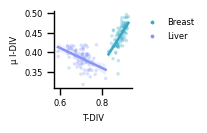

In [ ]:
nnow()
fig, ax = plt.subplots(figsize=(0.75,0.75))

for t in ['Breast','Liver']:
    sns.regplot(data = metadata.loc[metadata.SMTS == t], x = 'div', y = 'meanisofdiv', color = smts_palette[t], scatter_kws= {'edgecolor': 'none', 'alpha': 0.3, 's': 6, 'marker': 'h'}, ax =ax)

sns.despine()

legend_handles = [

    Line2D([], [], marker='h', linestyle='None', markerfacecolor=smts_palette[t],
           markeredgecolor='none', markersize=3, label=t)
    for t in smts_palette.keys() if t in ['Breast','Liver']
    
    ]
ax.legend(handles=legend_handles, bbox_to_anchor =(1.05, 1), loc='upper left', fontsize=6, ncols=1, frameon=False)


ax.set(ylabel='µ I-DIV', xlabel='T-DIV')
style_axis(ax)
fig.savefig(pth + 'figs_tdiv/' + 'SMTS.pearson_slope_examples.png', format='png', dpi=300, bbox_inches='tight')
s=f''' 
scatterplot showing mean isoform diversity (y axis) VS transcriptome diversity (x axis). 
scatterplot of breast (nsamples = {len(metadata.loc[metadata.SMTS == 'Breast'])}) and liver (nsamples = {len(metadata.loc[metadata.SMTS == 'Liver'])})
      '''
print(s)
with open(pth + 'figs_tdiv/' + 'SMTS.pearson_slope_examples.about.txt', 'w') as f:
    f.write(s)
    f.close()

# Donovan 2020: cell composition

In [ ]:
if not os.path.isdir(pth + 'figs_tdiv/' + 'Donovan/'):
    os.mkdir(pth + 'figs_tdiv/' + 'Donovan/')

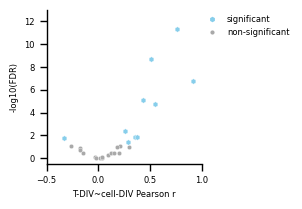

In [ ]:

fig, ax = plt.subplots(figsize=(2,2))
sns.scatterplot(data = cellular_div_corr_transcriptome_div[cellular_div_corr_transcriptome_div.fdr > 0.05].reset_index(), x = 'coefficient', y = 'mlogpfdr', color='darkgrey', s = 10, label='other')
sns.scatterplot(data = cellular_div_corr_transcriptome_div[cellular_div_corr_transcriptome_div.fdr <= 0.05].reset_index(), x = 'coefficient', y = 'mlogpfdr', color='skyblue', s=16)
ax.set(xlabel = 'T-DIV~cell-DIV Pearson r', ylabel = '-log10(FDR)')

legend_handles = [Line2D([], [], marker='.', linestyle='None', markerfacecolor='skyblue', markeredgecolor='none', markersize=6, label='significant')] + \
       [Line2D([], [], marker='.', linestyle='None', markerfacecolor='darkgrey', markeredgecolor='none', markersize=6, label='non-significant')] 

ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1.6,1), ncols=1)
ax.set_ylim(-0.5, 13)
ax.set_xticks([-0.5,0,0.5,1])
# ax.set_xticklabelss([-0.5,0,0.5,1])
style_axis(ax)
sns.despine()
fig.savefig(pth + 'figs_tdiv/Donovan/' + 'Donovan.volcanoplot.nohue.png', format = 'png', dpi = 300, bbox_inches='tight', pad_inches=0.4)

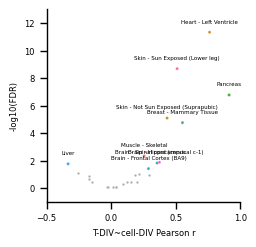

In [ ]:
sig_df = (
    cellular_div_corr_transcriptome_div.reset_index()
    .rename(columns={'index': 'SMTSD'})
    .copy()
)

sig_df = sig_df.loc[sig_df['fdr'] <= 0.05]

non_sig_df = (
    cellular_div_corr_transcriptome_div.reset_index()
    .rename(columns={'index': 'SMTSD'})
    .copy()
)

non_sig_df = non_sig_df.loc[non_sig_df['fdr'] > 0.05]

fig, ax = plt.subplots(figsize=(2.5, 2.5))

sns.scatterplot(
    data=non_sig_df,
    x='coefficient',
    y='mlogpfdr',
    color='darkgrey',
    s=3,
    ax=ax
)

sns.scatterplot(
    data=sig_df,
    x='coefficient',
    y='mlogpfdr',
    hue='SMTSD',
    palette=cell_composition_palette,
    marker='h',
    s=6,
    legend=False,
    ax=ax
)

for _, row in sig_df.iterrows():
    ax.annotate(
        row['SMTSD'],
        (row['coefficient'], row['mlogpfdr']),
        textcoords='offset points',
        xytext=(0, 6),
        fontsize=4,
        color='black',
        ha='center',
        va='bottom'
    )

ax.set(xlabel='T-DIV~cell-DIV Pearson r', ylabel='-log10(FDR)')
ax.set_ylim(-1, 13)
ax.set_xticks([-0.5, 0, 0.5, 1])
style_axis(ax)
sns.despine()

# fig.savefig(
#     pth + 'figs_tdiv/' + 'Donovan.volcanoplot.annotated.png',
#     format='png',
#     dpi=300,
#     bbox_inches='tight',
#     pad_inches=0.4
# )

In [ ]:
plot_df = cellular_div_corr_transcriptome_div.reset_index()
plot_df = plot_df.rename(columns={plot_df.columns[0]: 'SMTSD'})
plot_df['significance'] = np.where(plot_df['fdr'] <= 0.05, 'Significant', 'Not significant')

fig = px.scatter(
    plot_df,
    x='coefficient',
    y='mlogpfdr',
    color='significance',
    color_discrete_map={'Significant': 'skyblue', 'Not significant': 'darkgrey'},
    hover_name='SMTSD',
    hover_data={'coefficient': ':.3f', 'mlogpfdr': ':.3f', 'fdr': ':.3g', 'significance': False},
    labels={
        'coefficient': 'T-DIV ~ cell-DIV Pearson r',
        'mlogpfdr': '-log10(FDR)',
        'significance': 'Significance'
    }
)

fig.update_layout(
    template='simple_white',
    width=650,
    height=500
)
fig.show()

In [144]:
# sig_corrs = cellular_div_corr_transcriptome_div[cellular_div_corr_transcriptome_div.fdr <= 0.05].index
# cell_composition_palette = {t: smtsd_palette[t] if t in sig_corrs else 'dimgrey' for t in cellular_div_corr_transcriptome_div.index}

# import plotly.express as px
# import plotly.graph_objects as go
# alpha = 0.5
# fig1 = px.scatter(cellular_div_corr_transcriptome_div[cellular_div_corr_transcriptome_div.fdr > 0.05].reset_index(), x = 'coefficient', y = 'mlogpfdr', 
#                 opacity = alpha,  hover_data=['index'],color_discrete_sequence=['silver'],
#                 width = 500 , height=500)

# fig2 = px.scatter(cellular_div_corr_transcriptome_div[cellular_div_corr_transcriptome_div.fdr <= 0.05].reset_index(), x = 'coefficient', y = 'mlogpfdr', 
#                 opacity = 1,  hover_data=['index'], color_discrete_sequence=['hotpink'],
#                 width = 500 , height=500).update_traces(marker_symbol="hexagon")




# go.Figure(data=fig1.data + fig2.data).update_layout(width=500, height=500).update_traces(marker=dict(size=15))

In [9]:
len(metadata.loc[metadata.SMTSD=='Heart - Left Ventricle',['Donovan_cell_div', X, 'SMTSD']])

88

In [8]:
len(metadata.loc[metadata.SMTSD=='Pancreas',['Donovan_cell_div', X, 'SMTSD']])

26

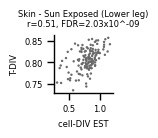

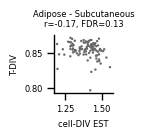

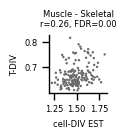

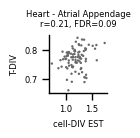

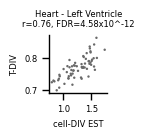

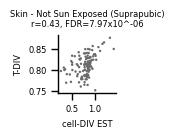

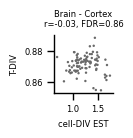

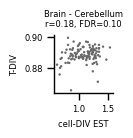

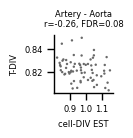

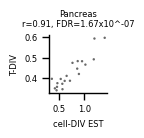

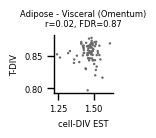

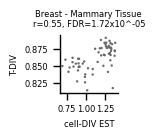

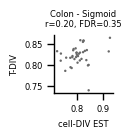

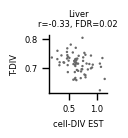

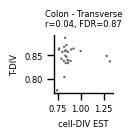

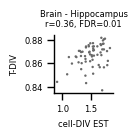

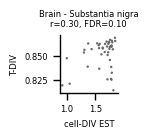

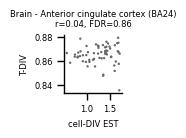

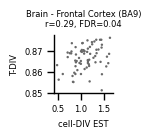

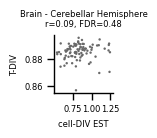

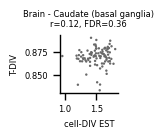

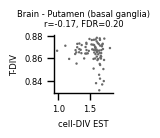

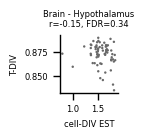

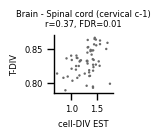

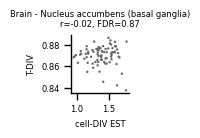

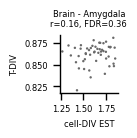

In [ ]:
for t in cellular_div_corr_transcriptome_div.index:
    fig, ax = plt.subplots(figsize=(0.5,0.5))
    sns.scatterplot(data = metadata.loc[metadata.SMTSD == t,['Donovan_cell_div', X, 'SMTSD']], 
                    x = 'Donovan_cell_div', y = X, s = 3, c='skyblue', edgecolor='None' ,ax =ax) # c = smtsd_palette[t]
    ax.set_title(t + '\n' + f'r={cellular_div_corr_transcriptome_div.loc[t, 'coefficient']:.2f}, FDR={format_small_number(cellular_div_corr_transcriptome_div.loc[t, 'fdr'])}')
    ax.set(ylabel = 'T-DIV', xlabel = 'cell-DIV EST')
    style_axis(ax)
    sns.despine()
    fig.savefig(pth + 'figs_tdiv/Donovan/' + 'Donovan.' + t + '.png', format = 'png', dpi = 300, bbox_inches='tight')

## HEART estimations

In [ ]:
cellular_compositions = {}
for i in [6,18]:
    
    ''' 
    Supplementary Data 5 legend. Cellular composition estimates of bulk RNA-seq from GTEx Heart (Atrial appendage) using mouse heart (subsetted to atrium cells) signature genes ;; i=6
    Supplementary Data 17 legend. Cellular composition estimates of bulk RNA-seq from GTEx Heart (Left ventricle) using mouse heart (subsetted to ventricle cells) signature genes ;; i=18    
    '''
    
    cellular_compositions[i] = pd.read_csv(f'/lustre1/home/martinmikl/sshanas/outsourcedata/input_files_git/Donovan2020/41467_2020_14561_MOESM{i}_ESM.csv', index_col='Input.Sample').join(metadata.SMTSD).assign(n = i).dropna().drop_duplicates()
    cell_columns = cellular_compositions[i].drop(columns = ['P.value', 'SMTSD','n']).columns
    cellular_compositions[i]['Donovan_cell_div'] = cellular_compositions[i].apply(lambda row: -1 * sum([row[col] * np.log(row[col])  for col in cell_columns if row[col] > 0 ])   , axis = 'columns')



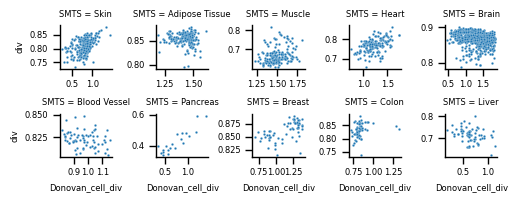

In [147]:
g = sns.FacetGrid(metadata.dropna(subset='Donovan_cell_div'), col='SMTS', col_wrap=5, height=1, sharex = False, sharey=False)
g.map_dataframe(sns.scatterplot, x = 'Donovan_cell_div', y = 'div', s = 3, )

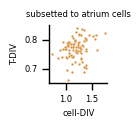

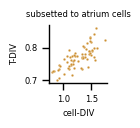

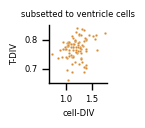

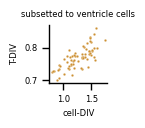

In [ ]:
for t in cellular_compositions[6].SMTSD.unique():
    fig, ax = plt.subplots(figsize=(0.5,0.5))
    sns.scatterplot(data = metadata.loc[metadata.SMTSD == t,['Donovan_cell_div', X, 'SMTSD']], 
                    x = 'Donovan_cell_div', y = X, s = 3, c = 'skyblue' ,ax =ax)
    ax.set_title(t + '\n' + f'r={cellular_div_corr_transcriptome_div.loc[t, 'coefficient']:.2f}, fdr={format_small_number(cellular_div_corr_transcriptome_div.loc[t, 'fdr'])}')
    ax.set(ylabel = 'T-DIV', xlabel = 'cell-DIV')
    style_axis(ax)
    sns.despine()
    fig.savefig(pth + 'figs_tdiv/Donovan/' + 'Donovan.' + t + 'subsetted_to_atrium_cells.png', format = 'png', dpi = 300, bbox_inches='tight')
for t in cellular_compositions[6].SMTSD.unique():
    fig, ax = plt.subplots(figsize=(0.5,0.5))
    sns.scatterplot(data = metadata.loc[metadata.SMTSD == t,['Donovan_cell_div', X, 'SMTSD']], 
                    x = 'Donovan_cell_div', y = X, s = 3, c = 'skyblue' ,ax =ax)
    ax.set_title(t + '\n' + f'r={cellular_div_corr_transcriptome_div.loc[t, 'coefficient']:.2f}, fdr={format_small_number(cellular_div_corr_transcriptome_div.loc[t, 'fdr'])}')
    ax.set(ylabel = 'T-DIV', xlabel = 'cell-DIV', title='subsetted to ventricle cells')
    style_axis(ax)
    sns.despine()
    fig.savefig(pth + 'figs_tdiv/Donovan/' + 'Donovan.' + t + '.subsetted_to_ventricle_cells.png', format = 'png', dpi = 300, bbox_inches='tight')

# transcriptome diversity/ mean isoform diversity correlation with geneTPM  

last time we used the correlation of: 
zscores on samples (mean = 0 & std = 1 per sample)  


In [19]:

nnow()
def enrichr_res(query_list, background_list, sign, var_in_corr):
    if len(query_list) > 0: 
        enr = gseapy.enrichr(gene_list=query_list, # or "./tests/data/gene_list.txt",
                        # gene_sets=['GO_Biological_Process_2025', 'GO_Cellular_Component_2025', 'GO_Molecular_Function_2025', 'Reactome_Pathways_2024', 'KEGG_2021_Human'], # enrichr library names  , 'Human_Phenotype_Ontology', 'KEGG_2021_Human'
                        gene_sets=['GO_Biological_Process_2025'],
                        background=background_list,
                        outdir=None) # don't write to disk
        enrichr_results = enr.results
        enrichr_results['-log10(Adjusted P-value)'] = -np.log10(enrichr_results['Adjusted P-value'])
        enrichr_results['-log10(P-value)'] = -np.log10(enrichr_results['P-value'])
        enrichr_results['QuerynGenes'] = len(query_list)
        enrichr_results['BGnGenes'] = len(background_list)
        enrichr_results['nGenesTerm'] = enrichr_results.Genes.str.count(';') + 1
        enrichr_results['trend'] = sign
        enrichr_results['var_in_corr'] = var_in_corr
        
        return enrichr_results

def correct_pvalues_with_nan(pvals, method='fdr_bh', alpha=0.05):
    pvals = np.asarray(pvals, dtype=float)
    mask = ~np.isnan(pvals)

    corrected = np.full_like(pvals, np.nan)
    reject = np.full(pvals.shape, False)

    if mask.sum() > 0:
        rej, pvals_corr, _, _ = multipletests(
            pvals[mask], alpha=alpha, method=method
        )
        corrected[mask] = pvals_corr
        reject[mask] = rej

    return reject, corrected


def count_tissues_sign(df):
    gene_tissue_significance = pd.DataFrame(index=df.index, columns=tissues_list, dtype=str)

    for c in tissues_list:
        coeff_col = c + '_coeff'
        # pval_col = c + '_pval'
        fdr_col = c + '_fdr'
        tissue_df = df.filter(like=c)
        if tissue_df.empty:
            continue

        # tissue_df = tissue_df.assign(fdr = st.false_discovery_control(tissue_df[pval_col], method='bh'))

        sign = pd.Series(index=tissue_df.index)
        sign.loc[(tissue_df[fdr_col] < 0.05) & (tissue_df[coeff_col] > 0)] = True
        sign.loc[(tissue_df[fdr_col] < 0.05) & (tissue_df[coeff_col] < 0)] = False

        gene_tissue_significance.loc[tissue_df.index, c] = sign

    gene_tissue_significance_counts = gene_tissue_significance.apply(
        lambda row: pd.Series({
            'nT': (row == True).sum(),
            'nF': (row == False).sum(),
            'nZ': (pd.isna(row)).sum()
        }),
        axis='columns'
    )

    gene_tissue_significance = gene_tissue_significance.join(gene_tissue_significance_counts)
    return gene_tissue_significance

def which_is_significant_enrichr(row):
    if (row['-log10(Adjusted P-value)_idiv'] > -np.log10(0.05)) and (row['-log10(Adjusted P-value)_tdiv'] > -np.log10(0.05)):
        return 'both'
    elif (row['-log10(Adjusted P-value)_idiv'] > -np.log10(0.05)) and (row['-log10(Adjusted P-value)_tdiv'] < -np.log10(0.05)):
        return 'idiv'
    elif (row['-log10(Adjusted P-value)_idiv'] < -np.log10(0.05)) and (row['-log10(Adjusted P-value)_tdiv'] > -np.log10(0.05)):
        return 'tdiv'
    else:
        return 'none'
    
def sign_for_scatterplot(row):
    if (row['enrichr_significance'] == 'both') and (row['trend_idiv'] == 1) and (row['trend_tdiv'] == 1):
        return '^'
    elif (row['enrichr_significance'] == 'both') and (row['trend_idiv'] == -1) and (row['trend_tdiv'] == -1):
        return 'v'
    elif (row['enrichr_significance'] == 'idiv') and (row['trend_idiv'] == 1):
        return '^'
    elif (row['enrichr_significance'] == 'idiv') and (row['trend_idiv'] == -1):
        return 'v'
    elif (row['enrichr_significance'] == 'tdiv') and (row['trend_tdiv'] == 1):
        return '^'
    elif (row['enrichr_significance'] == 'tdiv') and (row['trend_tdiv'] == -1):
        return 'v'
    else: # elif (row['enrichr_significance'] == 'none')
        return 's'


def pval_to_asterisks(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.01:
        return '**'
    elif p <= 0.05:
        return '*'
    else:
        return ''


def make_coef_and_asterisks_dfs(df, genenames_list):

    genesids = list(gene_info.loc[gene_info.gene_name.isin(genenames_list)].index)
    df_coef = df.loc[df['Unnamed: 0'].isin(genesids)].set_index('Unnamed: 0').filter(like='_coeff') # get coefficients
    df_coef.columns = [c.replace('_coeff','') for c in df_coef.columns]
    df_coef = df_coef.join(gene_info.loc[gene_info.gene_name.isin(genenames_list), 'gene_name'])
    df_coef.set_index('gene_name', inplace=True)
    
    df_fdr = df.loc[df['Unnamed: 0'].isin(genesids)].set_index('Unnamed: 0').filter(like='_pval') # get pvals
    df_fdr.columns = [c.replace('_pval','') for c in df_fdr.columns]
    df_fdr = df_fdr.join(gene_info.loc[gene_info.gene_name.isin(genenames_list), 'gene_name'])
    df_fdr.set_index('gene_name', inplace=True)
    
    for col in df_fdr.columns:
        df_fdr[col] = correct_pvalues_with_nan(df_fdr[col], alpha=0.05 ,method = 'fdr_bh')[1]
    df_fdr = df_fdr.applymap(pval_to_asterisks)
    return df_coef, df_fdr


def make_pair_heatmaps(cluster_matrix,genenames , termname,dirname ,yt=True):
    
    abb_SMTS = {t: t.replace(' Tissue', '').replace('Gland', 'G.').replace('Vessel', 'V.') for t in metadata.SMTS.unique()}
    '''
    cluster matrix: tdiv or idiv
    gene names: list
    dirname: idiv, tdiv or both (order by IDIV), both (order by TDIV)
    yt: should y ticks be included? Boolian
    '''
    
    iend=termname.find(' (GO')
    termname_f=termname[:iend]
    termname_f = termname_f.replace(" ", "_").replace(',','')

    idiv_coef, idiv_astr = make_coef_and_asterisks_dfs(df=idiv, genenames_list=genenames)
    tdiv_coef, tdiv_astr = make_coef_and_asterisks_dfs(df=tdiv, genenames_list=genenames)
    if cluster_matrix == 'idiv':
        cm = sns.clustermap(idiv_coef.fillna(0), cmap='bwr', center = 0)
        plt.close()
        idiv_coef = idiv_coef.iloc[cm.dendrogram_row.reordered_ind, cm.dendrogram_col.reordered_ind]
        idiv_astr = idiv_astr.reindex_like(idiv_coef)
        
        tdiv_coef = tdiv_coef.reindex_like(idiv_coef)
        tdiv_astr = tdiv_astr.reindex_like(idiv_coef)

    
    elif cluster_matrix == 'tdiv':
        cm = sns.clustermap(tdiv_coef.fillna(0), cmap='bwr', center = 0)
        plt.close()
        tdiv_coef = tdiv_coef.iloc[cm.dendrogram_row.reordered_ind, cm.dendrogram_col.reordered_ind]
        tdiv_astr = tdiv_astr.reindex_like(tdiv_coef)
        
        idiv_coef = idiv_coef.reindex_like(tdiv_coef)
        idiv_astr = idiv_astr.reindex_like(tdiv_coef)
    
    min_val = min(tdiv_coef.min().min(), idiv_coef.min().min())
    max_val = max(tdiv_coef.max().max(), idiv_coef.max().max())
    
    
    if not os.path.isdir(op + f'enriched_{dirname}/'):
        os.mkdir(op + f'enriched_{dirname}/')
    if not os.path.isdir(op + f'enriched_{dirname}/{termname_f}/'):
        os.mkdir(op + f'enriched_{dirname}/{termname_f}/')
    
    
    
    fig, ax = plt.subplots(figsize=(3,len(genenames)/10))
    sns.heatmap(idiv_coef.rename(columns={c:abb_SMTS[c] for c in idiv_coef.columns}), 
                annot=idiv_astr.rename(columns={c:abb_SMTS[c] for c in idiv_astr.columns}),
                cmap='bwr', center=0, vmin = min_val, vmax = max_val,
                yticklabels=yt,  fmt='', annot_kws={'fontsize': 4}, 
                cbar_kws={'label': 'I-DIV ~ TPM Pearson r'}, ax = ax)
    ax.set(ylabel = 'genes', xlabel = 'SMTS', title = termname)
    ax.tick_params(left=False, bottom=False) 
    
    fn = op + f'enriched_{dirname}/{termname_f}/n_{len(genenames)}.idiv_hm.png'
    
    fig.savefig(fn, format = 'png', dpi = 300, bbox_inches='tight', pad_inches=0.4)
    plt.close()
    
    fig, ax = plt.subplots(figsize=(3,len(genenames)/10))
    sns.heatmap(tdiv_coef.rename(columns={c:abb_SMTS[c] for c in tdiv_coef.columns}), 
                annot=tdiv_astr.rename(columns={c:abb_SMTS[c] for c in tdiv_astr.columns}),
                cmap='bwr', center=0, vmin = min_val, vmax = max_val,
                yticklabels=yt,  fmt='', annot_kws={'fontsize': 4} , 
                cbar_kws={'label': 'T-DIV ~ TPM Pearson r'}, ax = ax)
    ax.set(ylabel = 'genes', xlabel = 'SMTS', title = termname)
    ax.tick_params(left=False, bottom=False) 
    
    fn = op + f'enriched_{dirname}/{termname_f}/n_{len(genenames)}.tdiv_hm.png'
    fig.savefig(fn, format = 'png', dpi = 300, bbox_inches='tight', pad_inches=0.4)
    plt.close()

gene_group_color_palette = dict(zip(['idiv+', 'idiv-', 'tdiv+', 'tdiv-'], sns.color_palette('Paired', n_colors=4)))

2026-09-25  11:18:44


In [3]:
# metadata = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/pipeline_2025/outputdir.5/other_and_HK-RP/metadata.csv.gz', index_col=0)
# gene_info = pd.read_csv('/lustre1/home/martinmikl/sshanas/outsourcedata/pipeline_2025/outputdir.3/gene_metadata.csv.gz', index_col=0)


In [ ]:
tpm_correlations_with_transcriptomic_measures_pth = '/lustre1/home/martinmikl/sshanas/outsourcedata/GTEx_pre_downstream_git/fig3_tdiv_tpm_pearson/'
pth = '/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_trnscrptdiv_genetpm/'

sex_specific_t = ['Uterus', 'Breast', 'Testis', 'Ovary', 'Vagina' ,'Prostate']
nsex_specific_t = list(metadata[~metadata.SMTS.isin(sex_specific_t)].SMTS.unique())
c = ['Unnamed: 0'] + list(map(lambda x: x + '_coeff', nsex_specific_t)) + list(map(lambda x: x + '_pval', nsex_specific_t))

idiv = pd.read_csv(tpm_correlations_with_transcriptomic_measures_pth + 'pearson.mI-DIV.SMTS.csv', usecols = c).drop_duplicates('Unnamed: 0')
tdiv = pd.read_csv(tpm_correlations_with_transcriptomic_measures_pth + 'pearson.T-DIV.SMTS.csv', usecols = c).drop_duplicates('Unnamed: 0')

tissues_list = [c.replace('_coeff','') for c in idiv.filter(like='_coeff').columns]

for t in tissues_list:
    idiv[t + '_fdr'] = correct_pvalues_with_nan(idiv[t + '_pval'], alpha=0.05 ,method = 'fdr_bh')[1]
    tdiv[t + '_fdr'] = correct_pvalues_with_nan(tdiv[t + '_pval'], alpha=0.05 ,method = 'fdr_bh')[1]

count_idiv= count_tissues_sign(df=idiv.set_index('Unnamed: 0'))
count_tdiv= count_tissues_sign(df=tdiv.set_index('Unnamed: 0'))

# count_idiv.to_csv('tables_tdiv/r_counts.midiv.csv.gz', compression='gzip', index=True)
# count_tdiv.to_csv('tables_tdiv/r_counts.tdiv.csv.gz', compression='gzip', index=True)
count_idiv.to_csv(source_data_path + '3g_midiv.csv.gz', compression='gzip', index=True)
count_tdiv.to_csv(source_data_path + '3g_tdiv.csv.gz', compression='gzip', index=True)

In [ ]:

# pth = '/lustre1/home/martinmikl/sshanas/outsourcedata/downstream_2025_6/fast_1_2/corr_trnscrptdiv_genetpm/'

# sex_specific_t = ['Uterus', 'Breast', 'Testis', 'Ovary', 'Vagina' ,'Prostate']
# nsex_specific_t = list(metadata[~metadata.SMTS.isin(sex_specific_t)].SMTS.unique())
# c = ['Unnamed: 0'] + list(map(lambda x: x + '_coeff', nsex_specific_t)) + list(map(lambda x: x + '_pval', nsex_specific_t))

# idiv = pd.read_csv(pth + 'pearson.entire.mI-DIV.no_filter.SMTS.rows.csv', usecols = c).drop_duplicates('Unnamed: 0')
# tdiv = pd.read_csv(pth + 'pearson.entire.T-DIV.other_and_HK-RP.SMTS.rows.csv', usecols = c).drop_duplicates('Unnamed: 0')
# count_idiv = pd.read_csv('tables_tdiv/r_counts.midiv.csv.gz', compression='gzip', index_col='Unnamed: 0')
# count_tdiv = pd.read_csv('tables_tdiv/r_counts.tdiv.csv.gz', compression='gzip', index_col='Unnamed: 0')
# tissues_list = [c.replace('_coeff','') for c in idiv.filter(like='_coeff').columns]


In [22]:
''' test of normal distirubion in coefficients ''' 
nnow()

idiv_coeff_isnormal = pd.DataFrame(st.normaltest(idiv.set_index('Unnamed: 0').filter(like = '_coeff'), axis = 0), columns = idiv.set_index('Unnamed: 0').filter(like = '_coeff').columns, index = ['statistic_idiv', 'pval_idiv']).T
tdiv_coeff_isnormal = pd.DataFrame(st.normaltest(tdiv.set_index('Unnamed: 0').filter(like = '_coeff'), axis = 0), columns = tdiv.set_index('Unnamed: 0').filter(like = '_coeff').columns, index = ['statistic_tdiv', 'pval_tdiv']).T

# Highlight p-values > 0.05 in yellow in the joined dataframe
result_df = idiv_coeff_isnormal.join(tdiv_coeff_isnormal)

# Create a function to highlight cells where pval columns are > 0.05
def highlight_pvals(val, col_name):
    if 'pval' in col_name and val > 0.05:
        return 'background-color: yellow'
    return ''

# Apply styling
styled_result = result_df.style.applymap(lambda val: highlight_pvals(val, result_df.columns[result_df.columns.get_loc(result_df.index.name)]) if hasattr(result_df, 'columns') else '', subset=result_df.columns[result_df.columns.str.contains('pval')])

# Simpler approach: use apply with axis
styled_result = result_df.style.apply(lambda row: ['background-color: yellow' if ('pval' in col and row[col] > 0.05) else '' for col in row.index], axis=1)

print(f'''conclusion: the coefficients distributions are not normal.''')
display(styled_result)

2026-09-25  11:19:24
conclusion: the coefficients distributions are not normal.


,statistic_idiv,pval_idiv,statistic_tdiv,pval_tdiv
Brain_coeff,5683.983284,0.000000,31602.089500,0.000000
Skin_coeff,62171.094704,0.000000,1941.775010,0.000000
Blood Vessel_coeff,1286.445402,0.000000,573.009413,0.000000
Adipose Tissue_coeff,3.325574,0.189610,370.278886,0.000000
Blood_coeff,19393.793626,0.000000,91362.288882,0.000000
Esophagus_coeff,43.020349,0.000000,282307.267310,0.000000
Muscle_coeff,764.738081,0.000000,5175.856228,0.000000
Heart_coeff,4965.720120,0.000000,440.436266,0.000000
Thyroid_coeff,81.533107,0.000000,118.035161,0.000000
Pituitary_coeff,0.815868,0.665023,2725.317493,0.000000


In [ ]:


if not os.path.isdir('figs_tdiv/pearsons_corrs/'):
    os.mkdir('figs_tdiv/pearsons_corrs/')
if not os.path.isdir('figs_tdiv/pearsons_corrs/histograms/'):
    os.mkdir('figs_tdiv/pearsons_corrs/histograms/')

for t in tissues_list:
    ''' histograms of only significant (fdr) coefficients ''' 
    histt_df = idiv.filter(like=t)
    # histt_df = histt_df.assign(**{t + '_fdr': st.false_discovery_control(histt_df[t + '_pval'], method='bh')})
    histt_df = histt_df.loc[histt_df[t + '_fdr'] < 0.05]
    histt_df = histt_df.assign(r_sign = lambda x: np.where(x[t+'_coeff'] >0, 'idiv+', 'idiv-'   ))
    fig, ax = plt.subplots(figsize=(0.5,0.5))
    sns.histplot(data = histt_df, y = t + '_coeff', bins=100, element='step', hue='r_sign', palette=gene_group_color_palette, 
                legend=False,ax =ax)
    ax.set(title=t, ylabel = 'µ I-DIV~TPM\npearson r', xlabel = 'number of genes')
    style_axis(ax)
    fig.savefig('figs_tdiv/pearsons_corrs/histograms/' + t + '.significant.idiv.png', 
                format = 'png', dpi = 300, bbox_inches='tight')
    plt.close()
    histt_df = tdiv.filter(like=t)
    # histt_df = histt_df.assign(**{t + '_fdr': st.false_discovery_control(histt_df[t + '_pval'], method='bh')})
    histt_df = histt_df.loc[histt_df[t + '_fdr'] < 0.05]
    histt_df = histt_df.assign(r_sign = lambda x: np.where(x[t+'_coeff'] >0, 'tdiv+', 'tdiv-'   ))
    fig, ax = plt.subplots(figsize=(0.5,0.5))
    sns.histplot(data = histt_df, y = t + '_coeff', bins=100, element='step', hue='r_sign', palette=gene_group_color_palette, 
                legend=False,ax =ax)
    ax.set(title=t, ylabel = 'T-DIV~TPM\npearson r', xlabel = 'number of genes')
    style_axis(ax)
    fig.savefig('figs_tdiv/pearsons_corrs/histograms/' + t + '.significant.tdiv.png', 
                format = 'png', dpi = 300, bbox_inches='tight')
    plt.close()


    ''' histograms of all coefficients ''' 
    fig, ax = plt.subplots(figsize=(0.5,0.5))
    sns.histplot(data = idiv, y = t + '_coeff', bins=100, element='step', color = 'silver', ax =ax)
    ax.set(title=t, ylabel = 'µ I-DIV~TPM\npearson r', xlabel = 'number of genes')
    style_axis(ax)
    fig.savefig('figs_tdiv/pearsons_corrs/histograms/' + t + '.idiv.png', 
                format = 'png', dpi = 300, bbox_inches='tight')
    plt.close()
    fig, ax = plt.subplots(figsize=(0.5,0.5))
    sns.histplot(data = tdiv, y = t + '_coeff', bins=100, element='step', color = 'silver', ax =ax)
    ax.set(title=t, ylabel = 'T-DIV~TPM\npearson r', xlabel = 'number of genes')
    style_axis(ax)
    fig.savefig('figs_tdiv/pearsons_corrs/histograms/' + t + '.tdiv.png', 
                format = 'png', dpi = 300, bbox_inches='tight')
    plt.close()

In [ ]:
# count_idiv = pd.read_csv('tables_tdiv/r_counts.midiv.csv.gz', compression='gzip', index_col='Unnamed: 0')
# count_tdiv = pd.read_csv('tables_tdiv/r_counts.tdiv.csv.gz', compression='gzip', index_col='Unnamed: 0')
# count_idiv

In [ ]:
''' make lists '''
nnow()
op = 'figs_tdiv/pearsons_corrs/'
if not os.path.isdir(op):
    os.mkdir(op)
t = 10 # threshold: genes should be found in at least 10 tissues showing the same significant trend (same pearsonr sign against same variable) to be in a group. the group will then be tested for enrichment.
cp = {True: 'tomato', False: 'royalblue'}
nd = {True: 'p', False: 'n'}
columns_list = ['Gene_set', 'Term', 'Adjusted P-value', '-log10(Adjusted P-value)', 'QuerynGenes', 'BGnGenes', 'nGenesTerm', 'sign', 'tissue']
    
if not os.path.isdir('tables_tdiv/pearsons_corrs/'):
    os.mkdir('tables_tdiv/pearsons_corrs/')
''' 1. assign gene groups '''
pos_idiv = list(gene_info.loc[count_idiv.loc[count_idiv.nT >= t].index, 'gene_name'].values)
neg_idiv = list(gene_info.loc[count_idiv.loc[count_idiv.nF >= t].index, 'gene_name'].values)

pos_tdiv = list(gene_info.loc[count_tdiv.loc[count_tdiv.nT >= t].index, 'gene_name'].values)
neg_tdiv = list(gene_info.loc[count_tdiv.loc[count_tdiv.nF >= t].index, 'gene_name'].values)

count_genegroups = pd.DataFrame()
count_genegroups.loc['idiv+','number of genes'] = int(len(pos_idiv))
count_genegroups.loc['idiv-','number of genes'] = int(len(neg_idiv))
count_genegroups.loc['tdiv+','number of genes'] = int(len(pos_tdiv))
count_genegroups.loc['tdiv-','number of genes'] = int(len(neg_tdiv))
count_genegroups = count_genegroups.rename_axis('gene group').reset_index()
count_genegroups['number of genes'] = count_genegroups['number of genes'].astype(int)
count_genegroups.to_csv('tables_tdiv/pearsons_corrs/genegroup.count.csv.gz', compression='gzip', index=True)

fig, ax = plt.subplots(figsize=(0.5,0.5))
sns.barplot(data = count_genegroups, y = 'gene group', x = 'number of genes', hue='gene group', palette=gene_group_color_palette) 
for i in count_genegroups.index:
    plt.text(y=count_genegroups.loc[i, 'gene group'], x = count_genegroups.loc[i, 'number of genes'] + 100, s=f'{count_genegroups.loc[i, 'number of genes']:,}',
             va='center', fontsize=6)
sns.despine()
style_axis(ax)

fig.savefig(op + 'genegoup_count.png', dpi=300, bbox_inches='tight', format='png')

gene_info['idiv+'] = gene_info.index.isin(pos_idiv)
gene_info['idiv-'] = gene_info.index.isin(neg_idiv)
gene_info['tdiv+'] = gene_info.index.isin(pos_tdiv)
gene_info['tdiv-'] = gene_info.index.isin(neg_tdiv)
gene_info.to_csv('tables_tdiv/pearsons_corrs/genegroup.geneinfo.csv.gz', compression='gzip', index=True)

''' process enrichr '''

    
enrichr_dict = {}
enrichr_dict['idiv+'] = enrichr_res(query_list = pos_idiv, background_list = list(gene_info.gene_name.values), sign = True, var_in_corr='I-DIV')
enrichr_dict['idiv-'] = enrichr_res(query_list = neg_idiv, background_list = list(gene_info.gene_name.values), sign = False, var_in_corr='I-DIV')
enrichr_dict['tdiv+'] = enrichr_res(query_list = pos_tdiv, background_list = list(gene_info.gene_name.values), sign = True, var_in_corr='T-DIV')
enrichr_dict['tdiv-'] = enrichr_res(query_list = neg_tdiv, background_list = list(gene_info.gene_name.values), sign = False, var_in_corr='T-DIV')
for k in enrichr_dict.keys():
    enrichr_dict[k].to_csv('tables_tdiv/pearsons_corrs/' + k + '.csv.gz', compression='gzip', index=True)
    enrichr_dict[k].to_csv('tables_main/' + k + '.personr_res' + '.csv.gz', compression='gzip', index=True)
for k in enrichr_dict.keys():
    enrichr_dict[k].loc[enrichr_dict[k].nGenesTerm < 10, '-log10(Adjusted P-value)']= 0
    enrichr_dict[k].loc[enrichr_dict[k].nGenesTerm < 10, 'Adjusted P-value']= 1
    
    enrichr_dict[k] = enrichr_dict[k].assign(issig= lambda x: x['Adjusted P-value'] <= 0.05, variable = k[0].upper() + 'DIV')
    enrichr_dict[k] = enrichr_dict[k].assign(varaiable_issig= lambda row: np.where(row['issig'] == True, row['variable'], False))

pd.concat([enrichr_dict[k] for k in enrichr_dict.keys()]).to_csv(source_data_path + '3ghS4b.csv.gz')
''' results '''

gs = 'GO_Biological_Process_2025'
''' scatterplot of enrichment p-values from all four groups '''
# c_t = 'gold' ; c_i = 'royalblue'
c_t = '#FFFF00' ; c_i = '#00FFFF'
neg_enrichr = pd.DataFrame(index = list(set(enrichr_dict['tdiv-'].Term.to_list() + enrichr_dict['idiv-'].Term.to_list())))
neg_enrichr = neg_enrichr.join(enrichr_dict['tdiv-'].set_index('Term')[['Adjusted P-value', '-log10(Adjusted P-value)']].add_suffix('_tdiv')).join(enrichr_dict['idiv-'].set_index('Term')[['Adjusted P-value', '-log10(Adjusted P-value)']].add_suffix('_idiv'))
neg_enrichr.fillna(1, inplace=True)

neg_enrichr = neg_enrichr.loc[ (neg_enrichr['Adjusted P-value_tdiv'] <= 0.05) |  (neg_enrichr['Adjusted P-value_idiv'] <= 0.05)]

pos_enrichr = pd.DataFrame(index = list(set(enrichr_dict['tdiv+'].Term.to_list() + enrichr_dict['idiv+'].Term.to_list())))
pos_enrichr = pos_enrichr.join(enrichr_dict['tdiv+'].set_index('Term')[['Adjusted P-value', '-log10(Adjusted P-value)']].add_suffix('_tdiv')).join(enrichr_dict['idiv+'].set_index('Term')[['Adjusted P-value', '-log10(Adjusted P-value)']].add_suffix('_idiv'))
pos_enrichr.fillna(1, inplace=True)

pos_enrichr = pos_enrichr.loc[ (pos_enrichr['Adjusted P-value_tdiv'] <= 0.05) |  (pos_enrichr['Adjusted P-value_idiv'] <= 0.05)]

if len(np.intersect1d(pos_enrichr.index, neg_enrichr.index)) != 0:
    print('try again.')
else:
    enrichr = pd.concat([pos_enrichr.assign(r = True), neg_enrichr.assign(r = False)])
    enrichr = enrichr.assign(tdiv_enr = enrichr['Adjusted P-value_tdiv'] <= 0.05, idiv_enr = enrichr['Adjusted P-value_idiv'] <= 0.05)
    print('success.')
    
del pos_enrichr, neg_enrichr
fig, ax = plt.subplots(figsize=(2,2))
sns.scatterplot(data = enrichr, x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', hue = 'idiv_enr', palette={True: c_i, False:c_t}, style='r', markers={True:'^', False:'v'}, alpha = 0.5, edgecolor='dimgrey', linewidth=0.05, s = 40,legend=False)
sns.scatterplot(data = enrichr, x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', hue = 'tdiv_enr', palette={True: c_t, False:c_i}, style='r', markers={True:'^', False:'v'}, alpha = 0.5, edgecolor='dimgrey', linewidth=0.05, s = 40,legend=False)

legend_handles = [Line2D([], [], marker='^', linestyle='None', markerfacecolor='darkgrey', markeredgecolor='none', markersize=4, alpha=1, label='r>0 in T-DIV, µ I-DIV or both'),
                Line2D([], [], marker='v', linestyle='None', markerfacecolor='darkgrey', markeredgecolor='none', markersize=4, alpha=1, label='r<0 in T-DIV, µ I-DIV or both'),
                ] + \
                [
                Line2D([], [], marker='.', linestyle='None', markerfacecolor=c_t, markeredgecolor='dimgrey', markeredgewidth=0.05, markersize=8, alpha=1, label=f'enriched terms with shared sign for significant Pearsonr r(T-DIV~TPM) in at least {t} SMTS tissues'),
                Line2D([], [], marker='.', linestyle='None', markerfacecolor=c_i, markeredgecolor='dimgrey', markeredgewidth=0.05, markersize=8, alpha=1, label=f'enriched terms with shared sign for significant Pearsonr r(µ I-DIV~TPM) in at least {t} SMTS tissues')
                ] 
ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1), ncols=1)
ax.set(title='', xlabel='-log10(FDR) enrichemnt term from TPM ~ µ I-DIV', ylabel='-log10(FDR) enrichemnt term from\n TPM ~ T-DIV')
style_axis(ax)
sns.despine()
nUniqueSignificantTerms = len(enrichr)

fig.savefig(op + f'{gs}.n_{nUniqueSignificantTerms}.png', format = 'png', dpi = 300, bbox_inches='tight', pad_inches=0.4) 
plt.close()

fig, ax = plt.subplots(figsize=(2,2))
sns.scatterplot(data = enrichr[enrichr['r'] == True], x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', hue = 'idiv_enr', palette={True: '#00FFFF', False:'#FFFF00'}, style='r', markers={True:'^', False:'v'}, alpha = 0.5, edgecolor='dimgrey', linewidth=0.05, s = 40,legend=False)
sns.scatterplot(data = enrichr[enrichr['r'] == True], x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', hue = 'tdiv_enr', palette={True: '#FFFF00', False:'#00FFFF'}, style='r', markers={True:'^', False:'v'}, alpha = 0.5, edgecolor='dimgrey', linewidth=0.05, s = 40,legend=False)

ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1), ncols=1)
ax.set(title='', xlabel='-log10(FDR) enrichemnt term from TPM ~ µ I-DIV', ylabel='-log10(FDR) enrichemnt term from\n TPM ~ T-DIV')
style_axis(ax)
sns.despine()
nUniquePosSignificantTerms = len(enrichr[enrichr['r'] == True])
fig.savefig(op + f'PearsonPos.n_{nUniquePosSignificantTerms}.png', format = 'png', dpi = 300, bbox_inches='tight', pad_inches=0.4) 


fig, ax = plt.subplots(figsize=(2,2))
sns.scatterplot(data = enrichr[enrichr['r'] == False], x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', hue = 'idiv_enr', palette={True: '#00FFFF', False:'#FFFF00'}, style='r', markers={True:'^', False:'v'}, alpha = 0.5, edgecolor='dimgrey', linewidth=0.05, s = 40,legend=False)
sns.scatterplot(data = enrichr[enrichr['r'] == False], x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', hue = 'tdiv_enr', palette={True: '#FFFF00', False:'#00FFFF'}, style='r', markers={True:'^', False:'v'}, alpha = 0.5, edgecolor='dimgrey', linewidth=0.05, s = 40,legend=False)

ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1), ncols=1)
ax.set(title='', xlabel='-log10(FDR) enrichemnt term from TPM ~ µ I-DIV', ylabel='-log10(FDR) enrichemnt term from\n TPM ~ T-DIV')

style_axis(ax)
sns.despine()

nUniqueNegSignificantTerms = len(enrichr[enrichr['r'] == False])

fig.savefig(op + f'PearsonNeg.n_{nUniqueNegSignificantTerms}.png', format = 'png', dpi = 300, bbox_inches='tight', pad_inches=0.4) 




enrichr.to_csv('tables_tdiv/enriched_terms_from_significant_correlations.csv.gz', compression='gzip', index=True)
enrichr.to_csv('tables_main/enriched_terms_from_significant_correlations.csv.gz', compression='gzip', index=True)
enrichr.to_csv(supplementary_data_path + '3h.csv.gz', compression='gzip', index=True)

# neg_enrichr = pd.concat([enrichr_dict['idiv-'], enrichr_dict['tdiv-']])
# pos_enrichr = pd.concat([enrichr_dict['idiv+'], enrichr_dict['tdiv+']])
''' name every group of enriched terms by the origin of correlation variable and coefficient'''

significant_terms =  {}
''' enrichemnt of neg corr in T-DIV only '''
significant_terms['tdiv-'] = enrichr.loc[(enrichr['r'] == False) & (enrichr['tdiv_enr'] == True) & (enrichr['idiv_enr'] == False)].index
''' enrichemnt of pos corr in T-DIV only '''
significant_terms['tdiv+'] = enrichr.loc[(enrichr['r'] == True) & (enrichr['tdiv_enr'] == True) & (enrichr['idiv_enr'] == False)].index

''' enrichemnt of neg corr in I-DIV only '''
significant_terms['idiv-'] = enrichr.loc[(enrichr['r'] == False) & (enrichr['tdiv_enr'] == False) & (enrichr['idiv_enr'] == True)].index
''' enrichemnt of pos corr in I-DIV only '''
significant_terms['idiv+'] = enrichr.loc[(enrichr['r'] == True) & (enrichr['tdiv_enr'] == False) & (enrichr['idiv_enr'] == True)].index

''' enrichemnt of neg corr in T-DIV and I-DIV '''
significant_terms['both-'] = enrichr.loc[(enrichr['r'] == False) & (enrichr['tdiv_enr'] == True) & (enrichr['idiv_enr'] == True)].index
''' enrichemnt of pos corr in T-DIV and I-DIV '''
significant_terms['both+'] = enrichr.loc[(enrichr['r'] == True) & (enrichr['tdiv_enr'] == True) & (enrichr['idiv_enr'] == True)].index



s = f''' 
number of significant terms that come up in at least one of the correlation tests (µI-DIV or T-DIV) in genes with shared correlation trend across at least 10 SMTS tissues: {nUniqueSignificantTerms}
number of significant terms coming from anti-correlated genes of TPM~T-DIV alone: {len(significant_terms['tdiv-'])}
number of significant terms coming from positive-correlated genes of TPM~T-DIV alone: {len(significant_terms['tdiv+'])}
number of significant terms coming from anti-correlated genes of TPM~µ I-DIV alone: {len(significant_terms['idiv-'])}
number of significant terms coming from positive-correlated genes of TPM~µ I-DIV alone: {len(significant_terms['idiv+'])}
number of significant terms coming from anti-correlated genes of TPM~T-DIV and TPM~µ I-DIV: {len(significant_terms['both-'])}
number of significant terms coming from positive-correlated genes of TPM~T-DIV and TPM~µ I-DIV: {len(significant_terms['both+'])}

'''
with open(op + f'{gs}.n_{nUniqueSignificantTerms}.txt', 'w') as f:
   f.write(s)
   f.close() 




''' heatmaps of the enriched terms for mean I-DIV '''

s='idiv-'
significant_df = enrichr_dict[s].loc[enrichr_dict[s].Term.isin(significant_terms[s])]
for i in significant_df.index:
    gns=significant_df.loc[i, 'Genes'].split(';')
    tterm=significant_df.loc[i, 'Term']

    make_pair_heatmaps(cluster_matrix='idiv',genenames= gns , termname = tterm,dirname='idiv',yt=True)

s='idiv+'
significant_df = enrichr_dict[s].loc[enrichr_dict[s].Term.isin(significant_terms[s])]
for i in significant_df.index:
    gns=significant_df.loc[i, 'Genes'].split(';')
    tterm=significant_df.loc[i, 'Term']

    make_pair_heatmaps(cluster_matrix='idiv',genenames= gns , termname = tterm,dirname='idiv',yt=True)

''' heatmaps of the enriched terms for T-DIV'''

s='tdiv-'
significant_df = enrichr_dict[s].loc[enrichr_dict[s].Term.isin(significant_terms[s])]
for i in significant_df.index:
    gns=significant_df.loc[i, 'Genes'].split(';')
    tterm=significant_df.loc[i, 'Term']
    
    make_pair_heatmaps(cluster_matrix='tdiv',genenames= gns , termname = tterm,dirname='tdiv',yt=True)

s='tdiv+'
significant_df = enrichr_dict[s].loc[enrichr_dict[s].Term.isin(significant_terms[s])]
for i in significant_df.index:
    gns=significant_df.loc[i, 'Genes'].split(';')
    tterm=significant_df.loc[i, 'Term']

    make_pair_heatmaps(cluster_matrix='tdiv',genenames= gns , termname = tterm,dirname='tdiv',yt=True)



''' heatmaps of the enriched terms for both'''    
s='both-'
genesfrom= 'idiv-'
significant_df = enrichr_dict[genesfrom].loc[enrichr_dict[genesfrom].Term.isin(significant_terms[s])]

for i in significant_df.index:
    
    gns=significant_df.loc[i, 'Genes'].split(';')
    tterm=significant_df.loc[i, 'Term']

    make_pair_heatmaps(cluster_matrix='tdiv',genenames= gns , termname = tterm,dirname='both_orderby_tdiv',yt=True)
    make_pair_heatmaps(cluster_matrix='idiv',genenames= gns , termname = tterm,dirname='both_orderby_tdiv',yt=True)

genesfrom= 'idiv+'
significant_df = enrichr_dict[genesfrom].loc[enrichr_dict[genesfrom].Term.isin(significant_terms[s])]

for i in significant_df.index:
    gns=significant_df.loc[i, 'Genes'].split(';')
    tterm=significant_df.loc[i, 'Term']

    make_pair_heatmaps(cluster_matrix='tdiv',genenames= gns , termname = tterm,dirname='both_orderby_tdiv',yt=True)
    make_pair_heatmaps(cluster_matrix='idiv',genenames= gns , termname = tterm,dirname='both_orderby_tdiv',yt=True)
    
s='both+'
genesfrom= 'idiv+'
significant_df = enrichr_dict[genesfrom].loc[enrichr_dict[genesfrom].Term.isin(significant_terms[s])]

for i in significant_df.index:
    gns=significant_df.loc[i, 'Genes'].split(';')
    tterm=significant_df.loc[i, 'Term']
    make_pair_heatmaps(cluster_matrix='tdiv',genenames= gns , termname = tterm,dirname='both_orderby_tdiv',yt=True)

genesfrom= 'idiv+'
significant_df = enrichr_dict[genesfrom].loc[enrichr_dict[genesfrom].Term.isin(significant_terms[s])]
for i in significant_df.index:
    gns=significant_df.loc[i, 'Genes'].split(';')
    tterm=significant_df.loc[i, 'Term']
    make_pair_heatmaps(cluster_matrix='tdiv',genenames= gns , termname = tterm,dirname='both_orderby_idiv',yt=True)

2026-09-21  10:53:14
success.


TypeError: only list-like objects are allowed to be passed to isin(), you passed a `str`

In [ ]:
# enrichr = pd.read_csv('tables_tdiv/enriched_terms_from_significant_correlations.csv.gz', index_col = 'Unnamed: 0')
# pos_enrichr = enrichr.loc[enrichr['r'] == True]
# neg_enrichr = enrichr.loc[enrichr['r'] == False]
# del enrichr

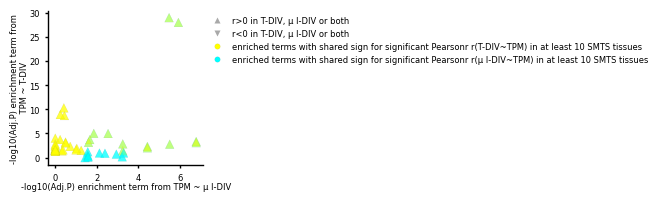

In [ ]:
# t=10
# fig, ax = plt.subplots(figsize=(2,2))
# sns.scatterplot(data = pos_enrichr, x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', hue = 'idiv_enr', palette={True: '#00FFFF', False:'#FFFF00'}, style='r', markers={True:'^', False:'v'}, alpha = 0.5, edgecolor='dimgrey', linewidth=0.05, s = 40,legend=False)
# sns.scatterplot(data = pos_enrichr, x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', hue = 'tdiv_enr', palette={True: '#FFFF00', False:'#00FFFF'}, style='r', markers={True:'^', False:'v'}, alpha = 0.5, edgecolor='dimgrey', linewidth=0.05, s = 40,legend=False)

# legend_handles = [Line2D([], [], marker='^', linestyle='None', markerfacecolor='darkgrey', markeredgecolor='none', markersize=4, alpha=1, label='r>0 in T-DIV, µ I-DIV or both'),
#                 Line2D([], [], marker='v', linestyle='None', markerfacecolor='darkgrey', markeredgecolor='none', markersize=4, alpha=1, label='r<0 in T-DIV, µ I-DIV or both'),
#                 ] + \
#                 [
#                 Line2D([], [], marker='.', linestyle='None', markerfacecolor='#FFFF00', markeredgecolor='dimgrey', markeredgewidth=0.05, markersize=8, alpha=1, label=f'enriched terms with shared sign for significant Pearsonr r(T-DIV~TPM) in at least {t} SMTS tissues'),
#                 Line2D([], [], marker='.', linestyle='None', markerfacecolor='#00FFFF', markeredgecolor='dimgrey', markeredgewidth=0.05, markersize=8, alpha=1, label=f'enriched terms with shared sign for significant Pearsonr r(µ I-DIV~TPM) in at least {t} SMTS tissues')
#                 ] 
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1), ncols=1)
# ax.set(title='', xlabel='-log10(Adj.P) enrichment term from TPM ~ µ I-DIV', ylabel='-log10(Adj.P) enrichment term from\n TPM ~ T-DIV')
# style_axis(ax)
# sns.despine()
# nUniquePosSignificantTerms = len(pos_enrichr)
# fig.savefig(op + f'PearsonPos.n_{nUniquePosSignificantTerms}.png', format = 'png', dpi = 300, bbox_inches='tight', pad_inches=0.4) 

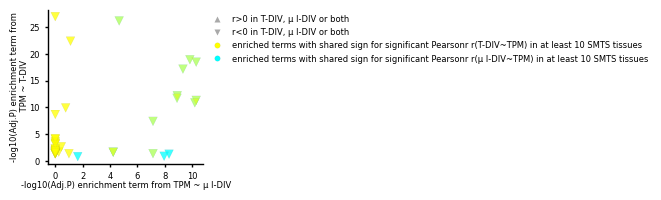

In [ ]:
# t=10
# fig, ax = plt.subplots(figsize=(2,2))
# sns.scatterplot(data = neg_enrichr, x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', hue = 'idiv_enr', palette={True: '#00FFFF', False:'#FFFF00'}, style='r', markers={True:'^', False:'v'}, alpha = 0.5, edgecolor='dimgrey', linewidth=0.05, s = 40,legend=False)
# sns.scatterplot(data = neg_enrichr, x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', hue = 'tdiv_enr', palette={True: '#FFFF00', False:'#00FFFF'}, style='r', markers={True:'^', False:'v'}, alpha = 0.5, edgecolor='dimgrey', linewidth=0.05, s = 40,legend=False)

# legend_handles = [Line2D([], [], marker='^', linestyle='None', markerfacecolor='darkgrey', markeredgecolor='none', markersize=4, alpha=1, label='r>0 in T-DIV, µ I-DIV or both'),
#                 Line2D([], [], marker='v', linestyle='None', markerfacecolor='darkgrey', markeredgecolor='none', markersize=4, alpha=1, label='r<0 in T-DIV, µ I-DIV or both'),
#                 ] + \
#                 [
#                 Line2D([], [], marker='.', linestyle='None', markerfacecolor='#FFFF00', markeredgecolor='dimgrey', markeredgewidth=0.05,  markersize=8, alpha=1, label=f'enriched terms with shared sign for significant Pearsonr r(T-DIV~TPM) in at least {t} SMTS tissues'),
#                 Line2D([], [], marker='.', linestyle='None', markerfacecolor='#00FFFF', markeredgecolor='dimgrey', markeredgewidth=0.05,  markersize=8, alpha=1, label=f'enriched terms with shared sign for significant Pearsonr r(µ I-DIV~TPM) in at least {t} SMTS tissues')
#                 ] 
# ax.legend(handles=legend_handles, frameon=False, fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1,1), ncols=1)
# ax.set(title='', xlabel='-log10(Adj.P) enrichment term from TPM ~ µ I-DIV', ylabel='-log10(Adj.P) enrichment term from\n TPM ~ T-DIV')

# style_axis(ax)
# sns.despine()

# nUniqueNegSignificantTerms = len(neg_enrichr)

# fig.savefig(op + f'PearsonNeg.n_{nUniqueNegSignificantTerms}.png', format = 'png', dpi = 300, bbox_inches='tight', pad_inches=0.4) 


In [ ]:
alpha = 0.5
c_t = '#FFFF00' ; c_i = '#00FFFF'
import plotly.express as px
import plotly.graph_objects as go

df = enrichr[enrichr['r'] == True].reset_index().rename(columns={'index': 'Term'})

fig1 = px.scatter(
    df,
    x='-log10(Adjusted P-value)_idiv',
    y='-log10(Adjusted P-value)_tdiv',
    color='tdiv_enr',
    symbol='r',
    color_discrete_map={True: c_t, False: c_i},
    symbol_map={True: 'triangle-up', False: 'triangle-down'},
    opacity=alpha,
    hover_data=['Term'],
    width=500, height=500
)
fig2 = px.scatter(
    df,
    x='-log10(Adjusted P-value)_idiv',
    y='-log10(Adjusted P-value)_tdiv',
    color='idiv_enr',
    symbol='r',
    color_discrete_map={True: c_i, False: c_t},
    symbol_map={True: 'triangle-up', False: 'triangle-down'},
    opacity=alpha,
    hover_data=['Term'],
    width=500, height=500
)

fig = go.Figure(data=fig2.data + fig1.data)
fig.update_traces(
    marker=dict(
        size=15,
        line=dict(color='dimgrey', width=0.05)   # marker edge
    )
)
fig.update_layout(
    width=500, height=500,
    legend_title_text=None,
    plot_bgcolor='white',
    paper_bgcolor='white',
    xaxis=dict(showgrid=False, zeroline=False, title='-log10(Adjusted P-value)_idiv'),
    yaxis=dict(showgrid=False, zeroline=False, title='-log10(Adjusted P-value)_tdiv'),
)


fig

In [ ]:
alpha = 0.5
c_t = '#FFFF00' ; c_i = '#00FFFF'
import plotly.express as px
import plotly.graph_objects as go

df = enrichr[enrichr['r'] == False].reset_index().rename(columns={'index': 'Term'})

fig1 = px.scatter(
    df,
    x='-log10(Adjusted P-value)_idiv',
    y='-log10(Adjusted P-value)_tdiv',
    color='tdiv_enr',
    symbol='r',
    color_discrete_map={True: c_t, False: c_i},
    symbol_map={True: 'triangle-up', False: 'triangle-down'},
    opacity=alpha,
    hover_data=['Term'],
    width=500, height=500
)
fig2 = px.scatter(
    df,
    x='-log10(Adjusted P-value)_idiv',
    y='-log10(Adjusted P-value)_tdiv',
    color='idiv_enr',
    symbol='r',
    color_discrete_map={True: c_i, False: c_t},
    symbol_map={True: 'triangle-up', False: 'triangle-down'},
    opacity=alpha,
    hover_data=['Term'],
    width=500, height=500
)

fig = go.Figure(data=fig2.data + fig1.data)
fig.update_traces(
    marker=dict(
        size=15,
        line=dict(color='dimgrey', width=0.05)   # marker edge
    )
)
fig.update_layout(
    width=500, height=500,
    legend_title_text=None,
    plot_bgcolor='white',
    paper_bgcolor='white',
    xaxis=dict(showgrid=False, zeroline=False, title='-log10(Adjusted P-value)_idiv'),
    yaxis=dict(showgrid=False, zeroline=False, title='-log10(Adjusted P-value)_tdiv'),
)


fig

In [38]:
fig1 = px.scatter(
    enrichr.reset_index().rename(columns={'index': 'Term'}),
    x='-log10(Adjusted P-value)_idiv',
    y='-log10(Adjusted P-value)_tdiv',
    color='tdiv_enr',            # column to map to color
    symbol='r',                  # column to map to marker shape
    color_discrete_map={True: c_t, False: c_i},  # explicit color mapping
    symbol_map={True: 'triangle-up', False: 'triangle-down'},  # explicit shape mapping
    opacity=alpha,
    hover_data=['Term'],
    width=500, height=500
)
fig2 = px.scatter(
    enrichr.reset_index().rename(columns={'index': 'Term'}),
    x='-log10(Adjusted P-value)_idiv',
    y='-log10(Adjusted P-value)_tdiv',
    color='tdiv_enr',            # column to map to color
    symbol='r',                  # column to map to marker shape
    color_discrete_map={True: c_i, False: c_t},  # explicit color mapping
    symbol_map={True: 'triangle-up', False: 'triangle-down'},  # explicit shape mapping
    opacity=alpha,
    hover_data=['Term'],
    width=500, height=500
)

go.Figure(data=fig2.data + fig1.data ).update_layout(width=500, height=500).update_traces(marker=dict(size=15)).update_layout(legend_title_text=None)


In [ ]:
# import plotly.express as px
# import plotly.graph_objects as go
# # fig, ax = plt.subplots(figsize=(2,2))
# alpha = 0.5
# fig1 = px.scatter(pos_enrichr[pos_enrichr.issig_idiv == True], x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', 
#                 opacity = alpha,  hover_data=['Term', 'nGenesTerm_idiv'],color_discrete_sequence=[c_i], width = 500 , height=500).update_traces(marker_symbol="triangle-up")

# fig2 = px.scatter(pos_enrichr[pos_enrichr.issig_tdiv == True], x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', 
#                 opacity = alpha,  hover_data=['Term', 'nGenesTerm_tdiv'], color_discrete_sequence=[c_t],
#                 width = 500 , height=500).update_traces(marker_symbol="triangle-up")

# fig3 = px.scatter(neg_enrichr[neg_enrichr.issig_idiv == True], x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', 
#                 opacity = alpha,  hover_data=['Term', 'nGenesTerm_idiv'], color_discrete_sequence=[c_i], 
#                 width = 500 , height=500).update_traces(marker_symbol="triangle-down")


# fig4 = px.scatter(neg_enrichr[neg_enrichr.issig_tdiv == True], x = '-log10(Adjusted P-value)_idiv', y = '-log10(Adjusted P-value)_tdiv', 
#                 opacity = alpha,  hover_data=['Term', 'nGenesTerm_tdiv'], color_discrete_sequence=[c_t],
#                 width = 500 , height=500).update_traces(marker_symbol="triangle-down")


# go.Figure(data=fig1.data + fig2.data + fig3.data + fig4.data).update_layout(width=500, height=500).update_traces(marker=dict(size=15))

### examples of specific genes

In [24]:
def show_genes(gene_name, tissue, dirname, gotrm,s):

    iend=gotrm.find(' (GO')
    termname_f=gotrm[:iend]
    termname_f = termname_f.replace(" ", "_").replace(',','')

    if not os.path.isdir(op + f'enriched_{dirname}/'):
        os.mkdir(op + f'enriched_{dirname}/')

    gid = gene_info.loc[gene_info.gene_name == gene_name].index[0]
    plotdf = metadata[['SMTS','meanisofdiv', 'div']].assign(**{gene_name:tpm.loc[gid]})
    plotdf = plotdf.loc[plotdf.SMTS == tissue]
    
    # if len(plotdf) < 40:
    #     alpha=0.7
    # else:
    #     alpha=0.2
    fig, ax = plt.subplots(figsize=(0.75,0.75))
    sns.scatterplot(data = plotdf, 
                    x = gene_name, y = 'div', 
                    s = 3, alpha=0.2,color='dimgrey', edgecolor=None)

    ax.set(title = ', '.join([f'r={tdiv.loc[tdiv['Unnamed: 0'] == gid, t + '_coeff'].values[0]:.2f}', annotpval(tdiv.loc[tdiv['Unnamed: 0'] == gid, tissue + '_fdr'].values[0]).replace('e', '^10')]).replace('p', 'FDR'), xlabel = 'TPM', ylabel = 'T-DIV') 
    style_axis(ax)
    
    fig.savefig(op + f'enriched_{dirname}/{termname_f}/{gene_name}.{tissue.replace(' ', '_')}.TDIV.png', format = 'png', dpi = 300, bbox_inches='tight')
    
    fig, ax = plt.subplots(figsize=(0.75,0.75))
    sns.scatterplot(data = plotdf, 
                    x = gene_name, y = 'meanisofdiv', 
                    s = 3, alpha=0.2,color='dimgrey', edgecolor=None)

    ax.set(title = ', '.join([f'r={idiv.loc[idiv['Unnamed: 0'] == gid, t + '_coeff'].values[0]:.2f}', annotpval(idiv.loc[idiv['Unnamed: 0'] == gid, tissue + '_fdr'].values[0]).replace('e', '^10')]).replace('p', 'FDR'), xlabel = 'TPM', ylabel = 'µ I-DIV') 
    style_axis(ax)
    
    fig.savefig(op + f'enriched_{dirname}/{termname_f}/{gene_name}.{tissue.replace(' ', '_')}.mIDIV.png', format = 'png', dpi = 300, bbox_inches='tight')
    s = f'''
    gene {gene_name} 
    term {gotrm} 
    SMTS tissue {tissue} 
    gene group {s}
    number of samples used (from a certein tissue and TPM>0): {len(plotdf)}
    
    global min r: {coef_df.stack().idxmin()}
    global max r: {coef_df.stack().idxmax()}
    '''

    with open(op + f'enriched_{dirname}/{termname_f}/{gene_name}.{tissue.replace(' ', '_')}.about.txt', 'w') as f:
        f.write(s)
        f.close()

In [ ]:
op = 'figs_tdiv/pearsons_corrs/'


In [ ]:
s='tdiv+'
significant_df = enrichr_dict[s].loc[enrichr_dict[s].Term.isin(significant_terms[s])]
for gotrm in enrichr.loc[(enrichr['r'] == True) & (enrichr.tdiv_enr == True) & (enrichr.idiv_enr == False)].index:
    coef_df, astr_df = make_coef_and_asterisks_dfs(df = tdiv, genenames_list = significant_df.loc[significant_df.Term == gotrm, 'Genes'].values[0].split(';'))
    # gn, t = coef_df.idxmax(axis='columns').idxmax(), coef_df.idxmax(axis='rows').idxmax()
    d = coef_df.idxmax().to_dict()
    for t, gn in d.items():
        show_genes(gene_name=gn, tissue=t, dirname='tdiv', gotrm=gotrm,s=s)

s='tdiv-'
significant_df = enrichr_dict[s].loc[enrichr_dict[s].Term.isin(significant_terms[s])]
for gotrm in enrichr.loc[(enrichr['r'] == False) & (enrichr.tdiv_enr == True) & (enrichr.idiv_enr == False)].index:
    coef_df, astr_df = make_coef_and_asterisks_dfs(df = tdiv, genenames_list = significant_df.loc[significant_df.Term == gotrm, 'Genes'].values[0].split(';'))
    # gn, t = coef_df.idxmin(axis='columns').idxmin(), coef_df.idxmin(axis='rows').idxmin()
    # show_genes(gene_name=gn, tissue=t, dirname='tdiv', gotrm=gotrm)
    d = coef_df.idxmin().to_dict()
    for t, gn in d.items():
        show_genes(gene_name=gn, tissue=t, dirname='tdiv', gotrm=gotrm,s=s)

In [ ]:
s='idiv+'
significant_df = enrichr_dict[s].loc[enrichr_dict[s].Term.isin(significant_terms[s])]
for gotrm in enrichr.loc[(enrichr['r'] == True) & (enrichr.tdiv_enr == False) & (enrichr.idiv_enr == True)].index:
    coef_df, astr_df = make_coef_and_asterisks_dfs(df = idiv, genenames_list = significant_df.loc[significant_df.Term == gotrm, 'Genes'].values[0].split(';'))
    # gn, t = coef_df.idxmax(axis='columns').idxmax(), coef_df.idxmax(axis='rows').idxmax()
    d = coef_df.idxmax().to_dict()
    for t, gn in d.items():
        show_genes(gene_name=gn, tissue=t, dirname='idiv', gotrm=gotrm,s=s)

s='idiv-'
significant_df = enrichr_dict[s].loc[enrichr_dict[s].Term.isin(significant_terms[s])]
for gotrm in enrichr.loc[(enrichr['r'] == False) & (enrichr.tdiv_enr == False) & (enrichr.idiv_enr == True)].index:
    coef_df, astr_df = make_coef_and_asterisks_dfs(df = idiv, genenames_list = significant_df.loc[significant_df.Term == gotrm, 'Genes'].values[0].split(';'))
    # gn, t = coef_df.idxmin(axis='columns').idxmin(), coef_df.idxmin(axis='rows').idxmin()
    # show_genes(gene_name=gn, tissue=t, dirname='idiv', gotrm=gotrm)
    d = coef_df.idxmin().to_dict()
    for t, gn in d.items():
        show_genes(gene_name=gn, tissue=t, dirname='idiv', gotrm=gotrm,s=s)

[Text(0.5, 1.0, 'r=-0.39, p=4.20^10-21'),
 Text(0.5, 0, 'TPM'),
 Text(0, 0.5, 'µ I-DIV')]

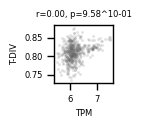

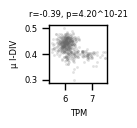

In [ ]:
gotrm = 'Mitochondrial Translation (GO:0032543)'
coef_df, astr_df = make_coef_and_asterisks_dfs(df = idiv, genenames_list = significant_df.loc[significant_df.Term == gotrm, 'Genes'].values[0].split(';'))
gn, t = coef_df.idxmin(axis='columns').idxmin(), coef_df.idxmin(axis='rows').idxmin()
show_genes(gene_name=gn, tissue=t, dirname='idiv', gotrm=gotrm,s=s)

In [ ]:
s='both+'
significant_df = enrichr_dict['tdiv+'].loc[enrichr_dict['tdiv+'].Term.isin(significant_terms[s])]
for gotrm in enrichr.loc[(enrichr['r'] == True) & (enrichr.tdiv_enr == True) & (enrichr.idiv_enr == True)].index:
    coef_df, astr_df = make_coef_and_asterisks_dfs(df = tdiv, genenames_list = significant_df.loc[significant_df.Term == gotrm, 'Genes'].values[0].split(';'))
    # gn, t = coef_df.idxmax(axis='columns').idxmax(), coef_df.idxmax(axis='rows').idxmax()
    # show_genes(gene_name=gn, tissue=t, dirname='both_orderby_tdiv', gotrm=gotrm)
    d = coef_df.idxmax().to_dict()
    for t, gn in d.items():
        show_genes(gene_name=gn, tissue=t, dirname='both_orderby_tdiv', gotrm=gotrm,s=s)

s='both-'
significant_df = enrichr_dict['tdiv-'].loc[enrichr_dict['tdiv-'].Term.isin(significant_terms[s])]
for gotrm in enrichr.loc[(enrichr['r'] == False) & (enrichr.tdiv_enr == True) & (enrichr.idiv_enr == True)].index:
    coef_df, astr_df = make_coef_and_asterisks_dfs(df = tdiv, genenames_list = significant_df.loc[significant_df.Term == gotrm, 'Genes'].values[0].split(';'))
    
    gn, t = coef_df.idxmin(axis='columns').idxmin(), coef_df.idxmin(axis='rows').idxmin()
    d = coef_df.idxmin().to_dict()
    for t, gn in d.items():
        show_genes(gene_name=gn, tissue=t, dirname='both_orderby_tdiv', gotrm=gotrm,s=s)

# PCA

In [ ]:
# nnow()
# from sklearn.decomposition import PCA
# from sklearn.metrics import silhouette_score
# from sklearn.preprocessing import StandardScaler

# def make_pca(metric, sample_list):
#     n_components = 2
#     pca = PCA(n_components=n_components)
#     scaler = StandardScaler()
    
#     scaled_features = scaler.fit_transform(metric.loc[:, sample_list  ].T)
#     pca_result = pd.DataFrame(pca.fit_transform(scaled_features), index = sample_list).join(metadata[['SMTS','SMTSD', X, 'meanisofdiv', 'meantpm', 'gt0']])
#     # pca_result = pd.DataFrame(pca.fit_transform(metric.loc[:, sample_list  ].T), index = sample_list).join(metadata[['SMTS','SMTSD', X, 'meanisofdiv', 'meantpm', 'gt0']])
#     var1 = pca.explained_variance_ratio_[0]
#     var2 = pca.explained_variance_ratio_[1]

#     label_dict = {l: i for i,l in enumerate(pca_result.SMTSD.unique())}
#     silhouette_sc = silhouette_score(pca_result[[0,1]].values, pca_result.SMTSD.map(label_dict))


#     # rank genes that drive separation
#     loadings = pd.DataFrame(
#         pca.components_.T, 
#         index=metric.index, 
#         columns=[f'PC{i+1}' for i in range(pca.n_components_)]).join(gene_info)


#     return pca_result, var1, var2, silhouette_sc, loadings

# colums_to_labels = {'gt0': 'nGenes', X: 'T-DIV', 'meanisofdiv':'µ I-DIV', 'meantpm': 'µ TPM'}

# pca_pth = 'figs_tdiv/pca/'

# if not os.path.isdir(pca_pth):
#     os.mkdir(pca_pth)

2026-09-14  09:44:27


2026-09-14  09:44:27
 
PCA based on TPM values.       
      


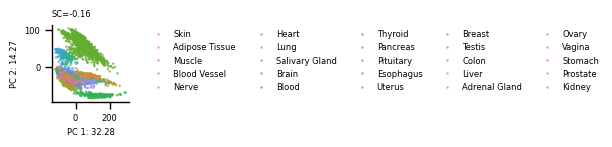

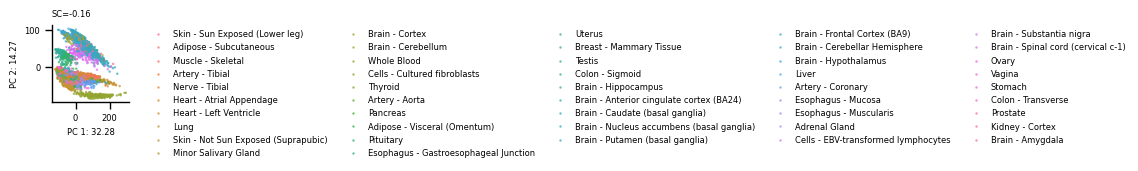

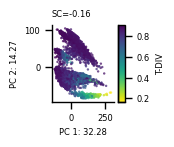

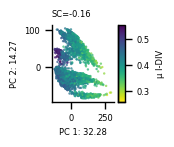

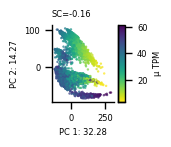

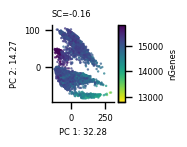

In [ ]:
# nnow()
# pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=tpm, sample_list=metadata.index)
# for h in ['SMTS', 'SMTSD', X, 'meanisofdiv', 'meantpm', 'gt0']:
#     fig, ax = plt.subplots(1,1, figsize=(1,1))    
#     if h == 'SMTS' or h =='SMTSD':
#         sns.scatterplot(data = pca_result, x = pca_result[0], y = pca_result[1], hue=h, edgecolor='none', alpha=0.75, s=3)
#         ax.legend(fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1.2,1), ncols=5, frameon=False)
#     else:
#         sns.scatterplot(data = pca_result, x = pca_result[0], y = pca_result[1], hue=h, edgecolor='none', alpha=0.75, s=3, palette='viridis_r', legend=False)
#         norm = plt.Normalize(pca_result[h].min(), pca_result[h].max())
#         sm = plt.cm.ScalarMappable(cmap="viridis_r", norm=norm)
#         sm.set_array([])
#         ax.figure.colorbar(sm, ax = ax, aspect= 10, label=colums_to_labels[h])

#     ax.set_title(f'SC={silhouette_sc:.2}', loc='left')
#     ax.set_xlabel('PC 1: ' + str(round(var1*100,2)))
#     ax.set_ylabel('PC 2: ' + str(round(var2*100,2)))
#     style_axis(ax)
#     sns.despine()
#     fig.savefig(pca_pth + '.'.join(['PCA', 'TPM_data','hue_' + h, 'png']), format='png', dpi=300, bbox_inches='tight')
# # 
# print(f''' 
# PCA based on TPM values.       
#       ''')


2026-09-14  09:44:41


 
PCA based on DIV values.      
      


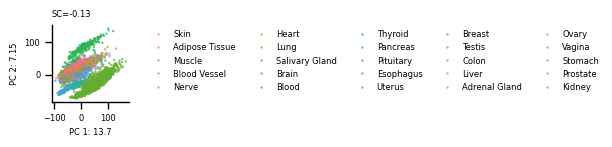

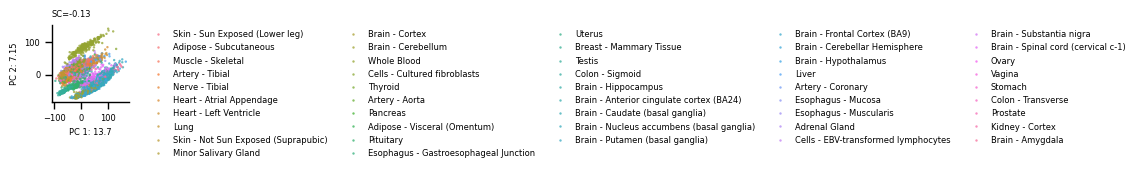

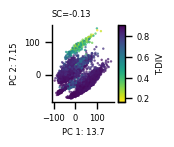

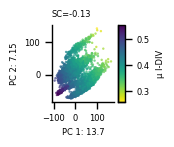

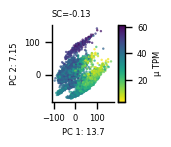

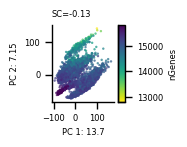

In [ ]:
# nnow()
# pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=div, sample_list=metadata.index)
# for h in ['SMTS', 'SMTSD', X, 'meanisofdiv', 'meantpm', 'gt0']:
#     fig, ax = plt.subplots(1,1, figsize=(1,1))
#     if h == 'SMTS' or h =='SMTSD':
#         sns.scatterplot(data = pca_result, x = pca_result[0], y = pca_result[1], hue=h, edgecolor='none', alpha=0.75, s=3)
#         ax.legend(fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1.2,1), ncols=5, frameon=False)
#     else:
#         sns.scatterplot(data = pca_result, x = pca_result[0], y = pca_result[1], hue=h, edgecolor='none', alpha=0.75, s=3, palette='viridis_r', legend=False)
#         norm = plt.Normalize(pca_result[h].min(), pca_result[h].max())
#         sm = plt.cm.ScalarMappable(cmap="viridis_r", norm=norm)
#         sm.set_array([])
#         ax.figure.colorbar(sm, ax = ax, aspect= 10, label=colums_to_labels[h])

#     ax.set_title(f'SC={silhouette_sc:.2}', loc='left')
#     ax.set_xlabel('PC 1: ' + str(round(var1*100,2)))
#     ax.set_ylabel('PC 2: ' + str(round(var2*100,2)))
#     style_axis(ax)
#     sns.despine()
#     fig.savefig(pca_pth + '.'.join(['PCA', 'I-DIV_data','hue_' + h, 'png']), format='png', dpi=300, bbox_inches='tight')
# print(f''' 
# PCA based on DIV values.      
#       ''')

2026-09-14  09:44:55


 
PCA based on NIS values.       
      


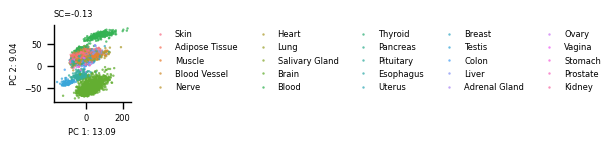

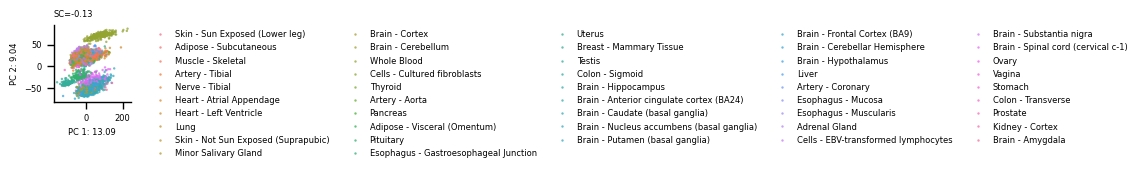

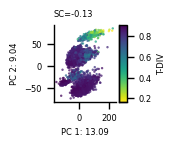

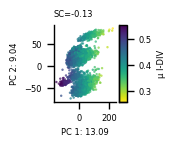

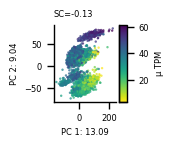

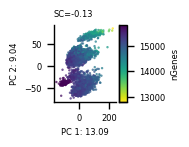

In [ ]:
# nnow()
# pca_result, var1, var2, silhouette_sc, loadings = make_pca(metric=nis, sample_list=metadata.index)
# for h in ['SMTS', 'SMTSD', X, 'meanisofdiv', 'meantpm', 'gt0']:
#     fig, ax = plt.subplots(1,1, figsize=(1,1))
    

    
#     if h == 'SMTS' or h =='SMTSD':
#         sns.scatterplot(data = pca_result, x = pca_result[0], y = pca_result[1], hue=h, edgecolor='none', alpha=0.75, s=3)
#         ax.legend(fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1.2,1), ncols=5, frameon=False)
#     else:
#         sns.scatterplot(data = pca_result, x = pca_result[0], y = pca_result[1], hue=h, edgecolor='none', alpha=0.75, s=3, palette='viridis_r', legend=False)
#         norm = plt.Normalize(pca_result[h].min(), pca_result[h].max())
#         sm = plt.cm.ScalarMappable(cmap="viridis_r", norm=norm)
#         sm.set_array([])
#         ax.figure.colorbar(sm, ax = ax, aspect= 10, label=colums_to_labels[h])


#     ax.set_title(f'SC={silhouette_sc:.2}', loc='left')
#     ax.set_xlabel('PC 1: ' + str(round(var1*100,2)))
#     ax.set_ylabel('PC 2: ' + str(round(var2*100,2)))
#     style_axis(ax)
#     sns.despine()
#     fig.savefig(pca_pth + '.'.join(['PCA', 'NIS_data','hue_' + h, 'png']), format='png', dpi=300, bbox_inches='tight')

# print(f''' 
# PCA based on NIS values.       
#       ''')

# boxplots per tissue of transcriptome diversity

In [3]:

def do_anova(group_lists_dict):
    if len(group_lists_dict.keys()) != 25:
        raise ValueError("Should correct if there are more or less than 25 groups")
    else:
        f, p = st.f_oneway(group_lists_dict['Pancreas'].dropna(), 
                           group_lists_dict['Blood'].dropna(),
                           group_lists_dict['Muscle'].dropna(), 
                           group_lists_dict['Pituitary'].dropna(),
                           group_lists_dict['Liver'].dropna(),
                           group_lists_dict['Salivary Gland'].dropna(), 
                           group_lists_dict['Stomach'].dropna(),
                           group_lists_dict['Heart'].dropna(),
                           group_lists_dict['Skin'].dropna(), 
                           group_lists_dict['Esophagus'].dropna(),
                           
                           group_lists_dict['Blood Vessel'].dropna(),
                           group_lists_dict['Colon'].dropna(), 
                           group_lists_dict['Adrenal Gland'].dropna(),
                           group_lists_dict['Lung'].dropna(),
                           group_lists_dict['Vagina'].dropna(), 
                           group_lists_dict['Adipose Tissue'].dropna(),
                           
                           group_lists_dict['Prostate'].dropna(),
                           group_lists_dict['Breast'].dropna(), 
                           group_lists_dict['Nerve'].dropna(),
                           group_lists_dict['Kidney'].dropna(),
                           group_lists_dict['Ovary'].dropna(), 
                           group_lists_dict['Brain'].dropna(),
                           
                           group_lists_dict['Uterus'].dropna(),
                           group_lists_dict['Thyroid'].dropna(), 
                           group_lists_dict['Testis'].dropna(),

                            
                        )
        df_between = len(group_lists_dict.keys()) - 1
        df_within = sum([len(v) for v in group_lists_dict.values()]) - len(group_lists_dict.keys())
        return f, p, df_between, df_within


    one-way ANOVA test for the effect of T-DIV on SMTS tissues. 
    F = 743.01, df between = 24, df within = 4789, p<10^-323  
    


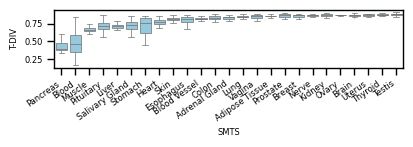

In [ ]:
# fig, ax = plt.subplots(figsize=(4.5,0.75))
fig, ax = plt.subplots(figsize=(0.75,2.3))

sns.boxplot(data=metadata, x = 'div', y = 'SMTS', order = metadata.groupby('SMTS')['div'].median().sort_values().index, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
            color='skyblue', fliersize=0.75, linewidth=0.5, ax=ax)


ax.set(xlabel='T-DIV')
f, p, df_between, df_within = do_anova(group_lists_dict = {t: metadata.loc[metadata.SMTS == t, 'div'] for t in metadata.SMTS.unique()})
print(
    f'''
    one-way ANOVA test for the effect of T-DIV on SMTS tissues. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    ''' )
style_axis(ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_yticklabels([abb_SMTS[y.get_text()] for y in ax.get_yticklabels()])
fig.savefig('figs_tdiv/T-DIV_SMTS.png', 
            format='png', dpi=300, bbox_inches='tight')


    one-way ANOVA test for the effect of TPM on clustered groups. 
    F = 233.96, df between = 24, df within = 4789, p<10^-323  
    


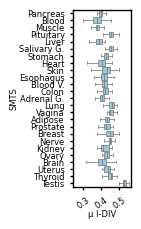

In [ ]:
# fig, ax = plt.subplots(figsize=(4.5,0.75))
fig, ax = plt.subplots(figsize=(0.75,2.3))

sns.boxplot(data=metadata, x = 'meanisofdiv', y = 'SMTS', order = metadata.groupby('SMTS')['div'].median().sort_values().index, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
            color='skyblue', fliersize=0.75, linewidth=0.5, ax=ax)

# ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')
ax.set(xlabel='µ I-DIV')
f, p, df_between, df_within = do_anova(group_lists_dict = {t: metadata.loc[metadata.SMTS == t, 'meanisofdiv'] for t in metadata.SMTS.unique()})

s=f'''
    one-way ANOVA test for the effect of TPM on clustered groups. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    '''
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_yticklabels([abb_SMTS[y.get_text()] for y in ax.get_yticklabels()])
style_axis(ax)
fig.savefig('figs_tdiv/mI-DIV_SMTS.png', 
            format='png', dpi=300, bbox_inches='tight')
with open(pth + f'mIDIV.about.txt', 'w') as file:
    file.write(s)
    file.close()


    one-way ANOVA test for the effect of TPM on clustered groups. 
    F = 283.68, df between = 24, df within = 4789, p<10^-323  
    


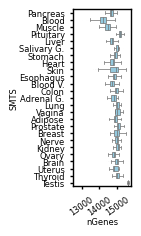

In [ ]:
fig, ax = plt.subplots(figsize=(0.75,2.3))

sns.boxplot(data=metadata, x = 'ngenes_expressed', y = 'SMTS', order = metadata.groupby('SMTS')['div'].median().sort_values().index, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
            color='skyblue', fliersize=0.75, linewidth=0.5, ax=ax)


ax.set(xlabel='nGenes')
f, p, df_between, df_within = do_anova(group_lists_dict = {t: metadata.loc[metadata.SMTS == t, 'ngenes_expressed'] for t in metadata.SMTS.unique()})
print(
    f'''
    one-way ANOVA test for the effect of TPM on clustered groups. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    ''' )
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_yticklabels([abb_SMTS[y.get_text()] for y in ax.get_yticklabels()])
style_axis(ax)
fig.savefig('figs_tdiv/gt0_SMTS.png', 
            format='png', dpi=300, bbox_inches='tight')

In [ ]:
fig, ax = plt.subplots(figsize=(0.75,2.3))

sns.boxplot(data=metadata, x = 'RP_div', y = 'SMTS', order = metadata.groupby('SMTS')['div'].median().sort_values().index, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
            color='skyblue', fliersize=0.75, linewidth=0.5, ax=ax)


ax.set(xlabel='nGenes')
f, p, df_between, df_within = do_anova(group_lists_dict = {t: metadata.loc[metadata.SMTS == t, 'RP_div'] for t in metadata.SMTS.unique()})
print(
    f'''
    one-way ANOVA test for the effect of TPM on clustered groups. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    ''' )
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_yticklabels([abb_SMTS[y.get_text()] for y in ax.get_yticklabels()])
style_axis(ax)
fig.savefig('figs_tdiv/RP_div_SMTS.png', 
            format='png', dpi=300, bbox_inches='tight')

In [ ]:
fig, ax = plt.subplots(figsize=(0.75,2.3))

sns.boxplot(data=metadata, x = '15834_div', y = 'SMTS', order = metadata.groupby('SMTS')['div'].median().sort_values().index, 
            flierprops={'marker':'D', 'markerfacecolor': 'silver', 'markeredgecolor': 'silver', 'alpha': 0.01, 'zorder':3, 'markersize': 0.1}, 
            color='skyblue', fliersize=0.75, linewidth=0.5, ax=ax)


ax.set(xlabel='nGenes')
f, p, df_between, df_within = do_anova(group_lists_dict = {t: metadata.loc[metadata.SMTS == t, '15834_div'] for t in metadata.SMTS.unique()})
print(
    f'''
    one-way ANOVA test for the effect of TPM on clustered groups. 
    F = {f:.2f}, df between = {df_between}, df within = {df_within}, {annotpval(p)}  
    ''' )
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_yticklabels([abb_SMTS[y.get_text()] for y in ax.get_yticklabels()])
style_axis(ax)
fig.savefig('figs_tdiv/15834_div_SMTS.png', 
            format='png', dpi=300, bbox_inches='tight')

In [ ]:
### correlation of median of  µ I-DIV against T-DIV, and nGenes against T-DIV 

In [6]:
metadata.columns

Index(['SEX', 'AGE', 'DTHHRDY', 'source', 'donor', 'SMTS', 'SMTSD',
       'SMNABTCHT', 'SMTSISCH', 'SMRIN', 'SMGEBTCH', 'age_decade',
       'age_grouped', 'system', 'ngenes_expressed',
       'ngenes_1percentile_HEG_div', 'ngenes_1percentile_HEG_gt0',
       'ngenes_1percentile_HEG_meantpm', 'ngenes_5percentile_HEG_div',
       'ngenes_5percentile_HEG_gt0', 'ngenes_5percentile_HEG_meantpm',
       'ngenes_10percentile_HEG_div', 'ngenes_10percentile_HEG_gt0',
       'ngenes_10percentile_HEG_meantpm', 'div',
       'ngenes_1percentile_HEG_meanisofdiv',
       'ngenes_5percentile_HEG_meanisofdiv',
       'ngenes_10percentile_HEG_meanisofdiv', 'ngenes_1percentile_HEG_meannis',
       'ngenes_5percentile_HEG_meannis', 'ngenes_10percentile_HEG_meannis',
       'meannis', 'percentile_ngenes_1', 'percentile_ngenes_5',
       'percentile_ngenes_10', 'AGE_grouped', 'AGE_int', 'div_norm', 'gt0',
       'meantpm', 'meanisofdiv', 'Donovan_cell_div'],
      dtype='object')

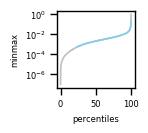

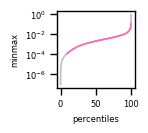

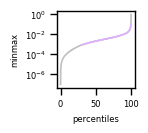

In [ ]:
pth = 'figs_tdiv/genegroups_div/'

smpl = metadata['div'].idxmax()
df_max = scale_with_MinMax(smpl = smpl)
df_max = df_max.join(gene_info[['RP_genes']])

smpl = metadata['div'].idxmin()
df_min = scale_with_MinMax(smpl = smpl)
df_min = df_min.join(gene_info[['RP_genes']])

fig, ax = plt.subplots(figsize=(0.75,0.75))
sns.lineplot(data = df_max, x = 'percentiles', y = 'minmax', c='silver', linewidth=2, zorder=0)
sns.scatterplot(data = df_max.loc[df_max.RP_genes == True], x = 'percentiles', y = 'minmax', c = 'skyblue', s=2, zorder=1)

sns.lineplot(data = df_min, x = 'percentiles', y = 'minmax', c='silver', linewidth=2, zorder=0)
sns.scatterplot(data = df_min.loc[df_min.RP_genes == True], x = 'percentiles', y = 'minmax', c = 'skyblue', s=2, zorder=1)


s = f'''
max T-DIV sample: {metadata['div'].idxmax()}
ngenes: {len(df_max)}
n RP genes: {len(df_max.loc[df_max.RP_genes == True])}
n intersect genes: {len(df_max.loc[df_max.HK_and_RP == True])}

min T-DIV sample: {metadata['div'].idxmin()}
ngenes: {len(df_min)}
n RP genes: {len(df_min.loc[df_min.RP_genes == True])}
n intersect genes: {len(df_min.loc[df_min.HK_and_RP == True])}
'''
with open(pth + 'min_max_TDIV.about.txt', 'w') as file:
    file.write(s)
    file.close()

KeyboardInterrupt: 

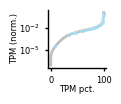

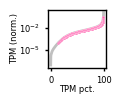

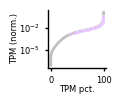

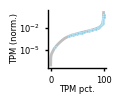

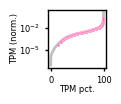

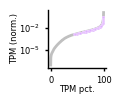

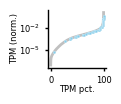

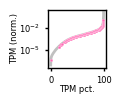

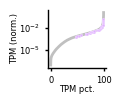

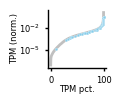

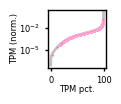

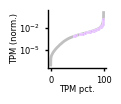

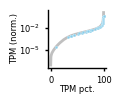

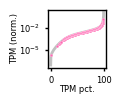

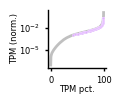

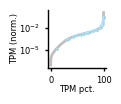

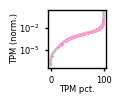

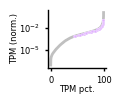

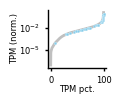

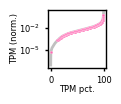

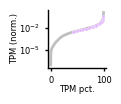

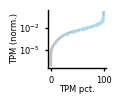

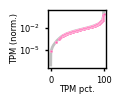

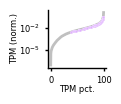

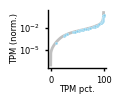

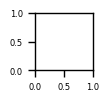

In [ ]:
pth = 'figs_tdiv/genegroups_div/'
def scale_with_MinMax_SMTSD(t):
    scaler = MinMaxScaler(feature_range=(10**-7, 1))
    plot_data = median_geneTPM[[t]]
    plot_data = plot_data[plot_data > 0].dropna().sort_values(plot_data.columns[0], ascending=False)

    plot_data = plot_data.assign(minmax = scaler.fit_transform(plot_data[[t]]))
    plot_data = plot_data.assign(percentiles = plot_data['minmax'].rank(pct=True) * 100).sort_values('minmax', ascending=True)
    return plot_data

median_geneTPM = tpm_untn.T.join(metadata.SMTSD).groupby('SMTSD').median()
median_geneTPM = median_geneTPM.T

for smtsd_t  in median_geneTPM.columns:
    fn = smtsd_t.replace('Brain - ', '').replace('(', '').replace(')', '')
    df = scale_with_MinMax_SMTSD(t=smtsd_t)
    df = df.join(gene_info[['RP_genes']])
    
    fig, ax = plt.subplots(figsize=(0.75,0.75))
    sns.lineplot(data = df, x = 'percentiles', y = 'minmax', c='silver', linewidth=2, zorder = 0)
    sns.scatterplot(data = df.loc[df.RP_genes == True], x = 'percentiles', y = 'minmax', c = 'skyblue', s=4, zorder = 1)
    style_axis(ax)
    ax.set_yscale('log')
    sns.despine()
    ax.set(ylabel='TPM (norm.)', xlabel='TPM pct.')
    fig.savefig(pth + '.'.join([fn,'RP_genes','png']), format='png', dpi=300, bbox_inches='tight')
    
    s = f'''{smtsd_t}
    number of genes used = {len(df)}
    number of ribosomal genes = {len(df.loc[df.RP_genes == True])}
    '''
    with open(pth + fn + '.about.txt', 'w') as file:
        file.write(s)
        # file.close()

### how I made the palletes

AttributeError: 'Line2D' object has no attribute 'get_facecolor'

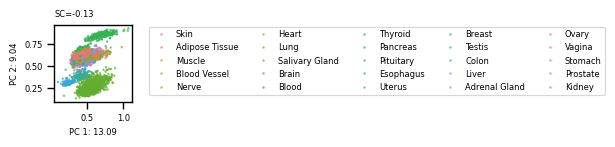

In [ ]:
# h='SMTS'
# fig, ax = plt.subplots(1,1, figsize=(1,1))

# ax.set_title(f'SC={silhouette_sc:.2}', loc='left')
# ax.set_xticklabels(ax.get_xticklabels(), ha='center')
# ax.set_yticklabels(ax.get_yticklabels())
# ax.set_xlabel('PC 1: ' + str(round(var1*100,2)))
# ax.set_ylabel('PC 2: ' + str(round(var2*100,2)))

# if h == 'SMTS' or h =='SMTSD':
#     sns.scatterplot(data = pca_result, x = pca_result[0], y = pca_result[1], hue=h, edgecolor='none', alpha=0.75, s=3)
#     ax.legend(fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1.2,1), ncols=5)


# hnd, lb = ax.get_legend_handles_labels()
# smts_palette= dict(zip(lb,[f.get_facecolor() for f in hnd]))

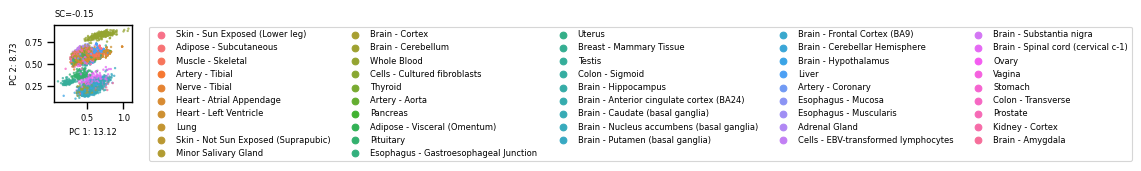

In [ ]:
# h='SMTSD'
# fig, ax = plt.subplots(1,1, figsize=(1,1))

# ax.set_title(f'SC={silhouette_sc:.2}', loc='left')
# ax.set_xticklabels(ax.get_xticklabels(), ha='center')
# ax.set_yticklabels(ax.get_yticklabels())
# ax.set_xlabel('PC 1: ' + str(round(var1*100,2)))
# ax.set_ylabel('PC 2: ' + str(round(var2*100,2)))

# if h == 'SMTS' or h =='SMTSD':
#     sns.scatterplot(data = pca_result, x = pca_result[0], y = pca_result[1], hue=h, edgecolor='none', alpha=0.75, s=3)
#     ax.legend(fontsize=6, borderaxespad=0.2, bbox_to_anchor=(1.2,1), ncols=5)


# hnd, lb = ax.get_legend_handles_labels()
# smtsd_palette= dict(zip(lb,[f.get_facecolor() for f in hnd]))

In [ ]:
# f = open("smts_palette.pkl","wb")
# pickle.dump(smts_palette,f) # write the python object (dict) to pickle file
# f.close()
# f = open("smtsd_palette.pkl","wb")
# pickle.dump(smtsd_palette,f) # write the python object (dict) to pickle file
# f.close()

# smts_palette = pickle.load(open('smts_palette.pkl', 'rb'))
# smtsd_palette = pickle.load(open('smtsd_palette.pkl', 'rb'))